# Parkinson'da tek destek süresi değişkenliği — çıktılı analiz defteri

**EEM4011 Biyomedikal Programlama · Nihat Akdeniz (223251056)**

Veri: PhysioNet *Gait in Parkinson's Disease* (GaitPDB) v1.0.0, ODC-By 1.0 — https://physionet.org/content/gaitpdb/1.0.0/. Kayıtlar internetten belleğe okunur; ham veri diske yazılmaz ve depoya konmaz.

Sorular: (a) Patoz ve ark. 2023'ün hız eşleştirmeli bulgusunun yeniden üretimi ve tüm örneklemde hız ayarı; (b) PD grubunda tek destek CV'sinin UPDRS ile hız ayarlı ilişkisi (birincil analiz); (c) hız eşleştirmesinin dışarıda bıraktığı hastalar farklı mı; (E11) sonuçlar olay tespiti eşiğine ne kadar bağlı.

Her kod hücresi `10_Analiz_Genisletilmis/` klasöründeki betiğin aynısıdır; defter boş klasörde baştan sona yeniden çalıştırılmıştır.

In [1]:
import sys, platform
sys.argv = ['defter', '1.25']   # dönüş tespiti tepe eşiği (doğrulama ölçüleriyle seçilen değer, bkz. DOGRULAMA_GUNLUGU.md)
import pandas, numpy, scipy, statsmodels, matplotlib
print('Python', platform.python_version(), '| pandas', pandas.__version__, '| numpy', numpy.__version__,
      '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| matplotlib', matplotlib.__version__)
%matplotlib inline

Python 3.12.10 | pandas 3.1.0 | numpy 2.5.4 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2


## Hücre 1 — Veri kontrolü
Demografi dosyasının ilk 20 sütunu okunur; hızı (`Speed_01`) dolu olan kişiler ve grupları sayılır.

In [2]:
import pandas as pd
import requests

URL = "https://physionet-open.s3.amazonaws.com/gaitpdb/1.0.0/"

dem = pd.read_csv(URL + "demographics.txt", sep="\t", usecols=range(20))
dem = dem[dem.ID.notna()]
dem["Grup"] = dem.Group.map({1: "PD", 2: "Kontrol"})

for sutun in ["Speed_01", "UPDRS", "HoehnYahr"]:
    print(f"\n{sutun} dolu / toplam:")
    print(dem.groupby(["Study", "Grup"])[sutun].agg(lambda s: f"{s.notna().sum()}/{len(s)}").unstack())

hizli = dem[dem.Speed_01.notna()].copy()
hizli["Patoz_araliginda"] = hizli.Speed_01.between(1.0, 1.3)
print("\nHızı dolu kişi:", hizli.Grup.value_counts().to_dict())
print("Patoz aralığında (1,0-1,3 m/s):")
print(hizli.groupby(["Grup", "Patoz_araliginda"]).size().unstack())

eksik_dosya = [k for k in hizli.ID if requests.head(URL + f"{k}_01.txt").status_code != 200]
print("\n_01 dosyası bulunamayan kişiler:", eksik_dosya)


Speed_01 dolu / toplam:
Grup  Kontrol     PD
Study               
Ga      18/18  28/29
Ju      26/26  29/29
Si      29/29  35/35

UPDRS dolu / toplam:
Grup  Kontrol     PD
Study               
Ga      18/18  29/29
Ju      26/26  29/29
Si       0/29  33/35

HoehnYahr dolu / toplam:
Grup  Kontrol     PD
Study               
Ga      18/18  29/29
Ju       0/26  29/29
Si       0/29  35/35

Hızı dolu kişi: {'PD': 92, 'Kontrol': 73}
Patoz aralığında (1,0-1,3 m/s):
Patoz_araliginda  False  True 
Grup                          
Kontrol              31     42
PD                   38     54



_01 dosyası bulunamayan kişiler: ['Juc010']


## Hücre 2 — Ön işleme ve olay bulmanın tek kişide kontrolü
Patoz ön işlemesi: 20 N altı sıfırlanır, 15 Hz 4. derece Butterworth süzgeci iki yönlü uygulanır (faz kayması olmaz), ilk 5 s atılır. Sağ ayak toplam kuvveti 20 N'yi yukarı geçince **basış**, aşağı geçince **parmak kalkışı** sayılır. Sol tek destek = sağ parmak kalkışından sonraki sağ basışa kadar geçen süre (bu sürede yalnız sol ayak yerdedir).

GaPt04 — sol tek destek süresi
  Eski yöntem (filtre yok, baştan atma yok): 94 aralık, ortalama 0.360 s, CV %15.85
  Patoz ön işlemesi (20 N + 15 Hz + ilk 5 s): 89 aralık, ortalama 0.368 s, CV %11.55
  En kısa / en uzun aralık (Patoz): 0.200 s / 0.480 s


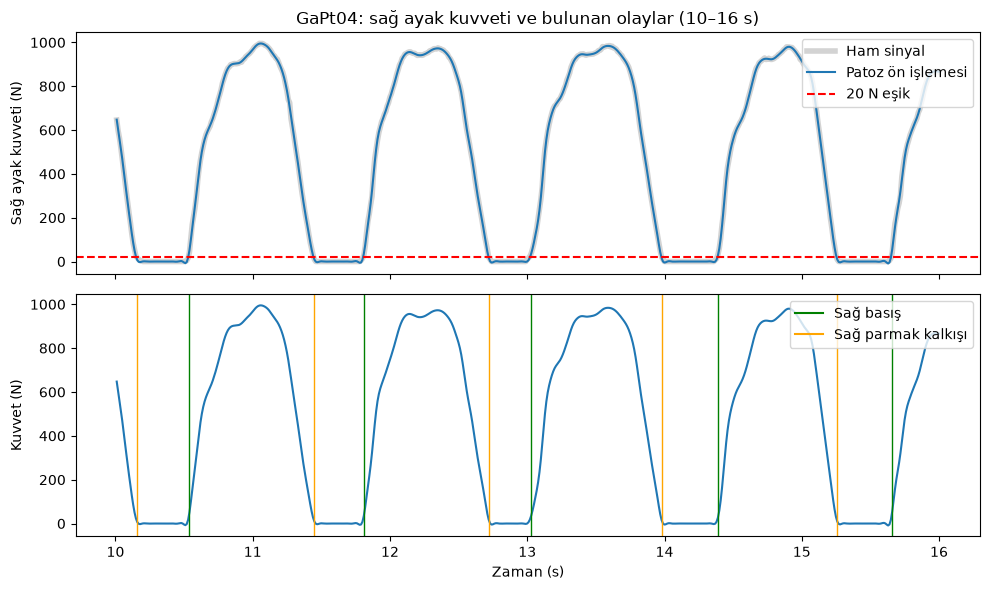

In [3]:
import io
import numpy as np
import requests
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

URL = "https://physionet-open.s3.amazonaws.com/gaitpdb/1.0.0/"
FS = 100        # örnekleme hızı (Hz)
ESIK = 20       # olay eşiği (N)
ATLA = 5        # baştan atılan süre (s)

def kayit_oku(kimlik):
    metin = requests.get(URL + f"{kimlik}_01.txt").text
    return np.loadtxt(io.StringIO(metin))

def patoz_on_isleme(kuvvet):
    k = np.where(kuvvet < ESIK, 0, kuvvet)
    b, a = butter(4, 15 / (FS / 2))
    return filtfilt(b, a, k)

def olaylar(kuvvet):
    yerde = kuvvet > ESIK
    basis = np.where(~yerde[:-1] & yerde[1:])[0] + 1
    kalkis = np.where(yerde[:-1] & ~yerde[1:])[0] + 1
    return basis, kalkis

def tek_destek(zaman, basis, kalkis):
    sureler = []
    for k in kalkis:
        sonraki = basis[basis > k]
        if len(sonraki) > 0:
            sureler.append(zaman[sonraki[0]] - zaman[k])
    return np.array(sureler)

def cv(x):
    return 100 * x.std(ddof=1) / x.mean()

kimlik = "GaPt04"
d = kayit_oku(kimlik)
zaman, sag = d[:, 0], d[:, 18]

ham_b, ham_k = olaylar(sag)
ham_ts = tek_destek(zaman, ham_b, ham_k)

bas = zaman >= ATLA
z2, sag_f = zaman[bas], patoz_on_isleme(sag)[bas]
f_b, f_k = olaylar(sag_f)
f_ts = tek_destek(z2, f_b, f_k)

print(f"{kimlik} — sol tek destek süresi")
print(f"  Eski yöntem (filtre yok, baştan atma yok): {len(ham_ts)} aralık, ortalama {ham_ts.mean():.3f} s, CV %{cv(ham_ts):.2f}")
print(f"  Patoz ön işlemesi (20 N + 15 Hz + ilk 5 s): {len(f_ts)} aralık, ortalama {f_ts.mean():.3f} s, CV %{cv(f_ts):.2f}")
print(f"  En kısa / en uzun aralık (Patoz): {f_ts.min():.3f} s / {f_ts.max():.3f} s")

pencere = (zaman >= 10) & (zaman <= 16)
fig, eks = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
eks[0].plot(zaman[pencere], sag[pencere], color="lightgray", lw=4, label="Ham sinyal")
eks[0].plot(z2[(z2 >= 10) & (z2 <= 16)], sag_f[(z2 >= 10) & (z2 <= 16)], color="tab:blue", label="Patoz ön işlemesi")
eks[0].axhline(ESIK, color="red", ls="--", label="20 N eşik")
eks[0].set_ylabel("Sağ ayak kuvveti (N)")
eks[0].legend(loc="upper right")
eks[0].set_title(f"{kimlik}: sağ ayak kuvveti ve bulunan olaylar (10–16 s)")
eks[1].plot(z2[(z2 >= 10) & (z2 <= 16)], sag_f[(z2 >= 10) & (z2 <= 16)], color="tab:blue")
for i in f_b:
    if 10 <= z2[i] <= 16:
        eks[1].axvline(z2[i], color="green", lw=1)
for i in f_k:
    if 10 <= z2[i] <= 16:
        eks[1].axvline(z2[i], color="orange", lw=1)
eks[1].plot([], [], color="green", label="Sağ basış")
eks[1].plot([], [], color="orange", label="Sağ parmak kalkışı")
eks[1].set_xlabel("Zaman (s)")
eks[1].set_ylabel("Kuvvet (N)")
eks[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig("sekil3_olay_kontrolu.png", dpi=150)
plt.show()

## Hücre 3 — 164 kişinin tek destek CV'si
CV = 100 × standart sapma (ddof = 1, örneklem standart sapması) / ortalama. 0,10 s'den kısa yer teması ya da havada kalma gürültü sayılır (kalite kuralı). Duyarlılık için eski yöntem, 50 N eşik, sağ ayak ve basit dönüş ayıklama da hesaplanır.

In [4]:
import io
import numpy as np
import pandas as pd
import requests
from scipy.signal import butter, filtfilt

URL = "https://physionet-open.s3.amazonaws.com/gaitpdb/1.0.0/"
FS, ATLA = 100, 5
B, A = butter(4, 15 / (FS / 2))

# Bu kurallar grup sonuçlarına bakılmadan önce yazıldı ve sonradan değiştirilmez.
# Ana yöntem: Patoz ön işlemesi (20 N altı sıfır, 15 Hz Butterworth, ilk 5 s atılır), 20 N olay eşiği.
# Duyarlılık: eski yöntem; 50 N olay eşiği; dönüş ayıklama (medyan ± 3 × ölçekli MAD dışı aralıklar atılır); sağ tek destek.
# Kalite kuralları (23 Ekim, ilk çalıştırmadaki kişi bazlı kontrolden sonra eklendi; grup karşılaştırması yapılmadan):
#  - 0,10 s'den kısa yer teması veya havada kalma gürültü sayılır (JuPt25'te salınımda ayak sürtmesi sahte olay üretiyordu).
#  - Dönüş ayıklamada ölçekli MAD en az 0,01 s alınır (10 ms çözünürlükte MAD = 0 olabiliyordu; SiCo15).
EN_KISA = 10    # örnek = 0,10 s

def kayit_oku(kimlik):
    return np.loadtxt(io.StringIO(requests.get(URL + f"{kimlik}_01.txt").text))

def on_isleme(kuvvet):
    return filtfilt(B, A, np.where(kuvvet < 20, 0, kuvvet))

def kisa_parcalari_sil(yerde, deger):
    # deger durumundaki EN_KISA'dan kısa ardışık parçaları karşı duruma çevirir
    yerde = yerde.copy()
    i = 0
    while i < len(yerde):
        if yerde[i] == deger:
            j = i
            while j < len(yerde) and yerde[j] == deger:
                j += 1
            if j - i < EN_KISA and i > 0 and j < len(yerde):
                yerde[i:j] = not deger
            i = j
        else:
            i += 1
    return yerde

def olaylar(kuvvet, esik, kural=True):
    yerde = kuvvet > esik
    if kural:
        yerde = kisa_parcalari_sil(kisa_parcalari_sil(yerde, True), False)
    basis = np.where(~yerde[:-1] & yerde[1:])[0] + 1
    kalkis = np.where(yerde[:-1] & ~yerde[1:])[0] + 1
    return basis, kalkis

def tek_destek(zaman, kuvvet_karsi, esik, kural=True):
    # Bir bacağın tek destek süresi = karşı ayağın kalkışından sonraki basışına kadar geçen süre
    basis, kalkis = olaylar(kuvvet_karsi, esik, kural)
    sureler = []
    for k in kalkis:
        sonraki = basis[basis > k]
        if len(sonraki) > 0:
            sureler.append(zaman[sonraki[0]] - zaman[k])
    return np.array(sureler)

def cv(x):
    return 100 * x.std(ddof=1) / x.mean() if len(x) > 2 else np.nan

def donus_ayikla(x):
    mad = max(1.4826 * np.median(np.abs(x - np.median(x))), 0.01)
    return x[np.abs(x - np.median(x)) <= 3 * mad]

dem = pd.read_csv(URL + "demographics.txt", sep="\t", usecols=range(20))
dem = dem[dem.ID.notna() & dem.Speed_01.notna() & (dem.ID != "Juc010")].copy()
dem["Grup"] = dem.Group.map({1: "PD", 2: "Kontrol"})

satirlar = []
for kimlik in dem.ID:
    d = kayit_oku(kimlik)
    zaman, sol, sag = d[:, 0], d[:, 17], d[:, 18]
    bas = zaman >= ATLA
    z, sol_f, sag_f = zaman[bas], on_isleme(sol)[bas], on_isleme(sag)[bas]
    ana = tek_destek(z, sag_f, 20)
    satirlar.append({
        "ID": kimlik,
        "n_aralik": len(ana),
        "ort_s": ana.mean(),
        "CV_ana": cv(ana),
        "CV_eski": cv(tek_destek(zaman, sag, 20, kural=False)),
        "CV_kuralsiz": cv(tek_destek(z, sag_f, 20, kural=False)),
        "CV_50N": cv(tek_destek(z, sag_f, 50)),
        "CV_donus_ayikli": cv(donus_ayikla(ana)),
        "n_donus_ayikli": len(donus_ayikla(ana)),
        "CV_sag_tek_destek": cv(tek_destek(z, sol_f, 20)),
        "kayit_s": zaman[-1],
    })

tablo = dem.merge(pd.DataFrame(satirlar), on="ID")
tablo["Patoz_araliginda"] = tablo.Speed_01.between(1.0, 1.3)
tablo.to_csv("kisi_cv_tum.csv", index=False)

print("Kişi sayısı:", tablo.Grup.value_counts().to_dict())
print("\nAralık sayısı (ana yöntem): en az", tablo.n_aralik.min(), "| medyan", int(tablo.n_aralik.median()), "| en çok", tablo.n_aralik.max())
print("30'dan az aralığı olan kişiler:", tablo.loc[tablo.n_aralik < 30, ["ID", "n_aralik", "kayit_s"]].values.tolist())
print("\nGrup ortalamaları (CV %):")
print(tablo.groupby("Grup")[["CV_ana", "CV_kuralsiz", "CV_eski", "CV_50N", "CV_donus_ayikli", "CV_sag_tek_destek"]].mean().round(2).T)
degisen = tablo[(tablo.CV_ana - tablo.CV_kuralsiz).abs() > 0.5]
print("\nKalite kuralının CV'yi 0,5 puandan fazla değiştirdiği kişiler:", len(degisen))
print(degisen[["ID", "CV_kuralsiz", "CV_ana"]].round(2).values.tolist())
print("\nAlt çalışmaya göre ana CV ortalaması:")
print(tablo.groupby(["Study", "Grup"]).CV_ana.mean().round(2).unstack())

Kişi sayısı: {'PD': 92, 'Kontrol': 72}

Aralık sayısı (ana yöntem): en az 32 | medyan 100 | en çok 164
30'dan az aralığı olan kişiler: []

Grup ortalamaları (CV %):
Grup               Kontrol     PD
CV_ana                7.82   9.89
CV_kuralsiz           9.60  12.45
CV_eski              15.97  20.27
CV_50N                6.96   9.33
CV_donus_ayikli       3.57   5.15
CV_sag_tek_destek     8.07   9.65

Kalite kuralının CV'yi 0,5 puandan fazla değiştirdiği kişiler: 48
[['GaPt05', 19.22, 12.48], ['GaPt07', 27.41, 21.03], ['GaPt08', 17.51, 10.8], ['GaPt09', 13.1, 10.6], ['GaPt13', 21.7, 13.49], ['GaPt15', 16.94, 12.19], ['GaPt24', 27.6, 12.16], ['GaPt25', 8.62, 12.31], ['GaPt26', 20.63, 9.75], ['GaPt30', 15.23, 10.84], ['GaPt33', 11.86, 8.18], ['JuPt04', 19.48, 10.93], ['JuPt06', 13.19, 7.21], ['JuPt10', 14.2, 9.76], ['JuPt11', 18.32, 14.54], ['JuPt13', 30.01, 20.56], ['JuPt18', 20.39, 19.25], ['JuPt21', 17.08, 12.39], ['JuPt22', 12.81, 6.73], ['JuPt23', 15.71, 12.24], ['JuPt25', 64.26, 19.

## Hücre 4 — Patoz ve ark. 2023'ün yeniden üretimi
Yalnız 1,0–1,3 m/s hızda yürüyenler alınır; PD ve kontrol Student ve Welch t-testleriyle karşılaştırılır.

In [5]:
import numpy as np
import pandas as pd
from scipy import stats

# Patoz ve ark. 2023: 1,0–1,3 m/s hızdaki katılımcılar, iki yönlü eşleştirilmemiş Student t-testi.
# Bildirilen tek destek süresi CV'si: PD %5,0 ± 2,1 (n = 54), kontrol %3,6 ± 1,1 (n = 39), p < 0,001.
PATOZ = {"PD": (5.0, 2.1, 54), "Kontrol": (3.6, 1.1, 39)}

tablo = pd.read_csv("kisi_cv_tum.csv")
es = tablo[tablo.Patoz_araliginda]

def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

print("Eşleştirilmiş örneklem:", es.Grup.value_counts().to_dict())
print("Ortalama hız (m/s):", es.groupby("Grup").Speed_01.mean().round(3).to_dict())
print("Hız farkı t-testi p =", round(stats.ttest_ind(es[es.Grup == "PD"].Speed_01, es[es.Grup == "Kontrol"].Speed_01).pvalue, 3))

satirlar = []
for olcu, ad in [("CV_donus_ayikli", "Dönüş ayıklamalı CV"), ("CV_ana", "Ana CV"), ("CV_sag_tek_destek", "Sağ tek destek CV"), ("ort_s", "Ortalama tek destek (s)")]:
    pd_ = es.loc[es.Grup == "PD", olcu]
    ko = es.loc[es.Grup == "Kontrol", olcu]
    student = stats.ttest_ind(pd_, ko)
    welch = stats.ttest_ind(pd_, ko, equal_var=False)
    satirlar.append({
        "Ölçü": ad,
        "PD ort ± SS": f"{pd_.mean():.2f} ± {pd_.std(ddof=1):.2f}",
        "Kontrol ort ± SS": f"{ko.mean():.2f} ± {ko.std(ddof=1):.2f}",
        "Fark": round(pd_.mean() - ko.mean(), 3),
        "Student p": f"{student.pvalue:.2g}",
        "Welch p": f"{welch.pvalue:.2g}",
        "Cohen d": round(cohen_d(pd_, ko), 2),
    })
sonuc = pd.DataFrame(satirlar)
print("\n" + sonuc.to_string(index=False))

pd_p, ko_p = PATOZ["PD"], PATOZ["Kontrol"]
sp = np.sqrt(((pd_p[2] - 1) * pd_p[1] ** 2 + (ko_p[2] - 1) * ko_p[1] ** 2) / (pd_p[2] + ko_p[2] - 2))
print(f"\nPatoz 2023 (bildirilen): PD {pd_p[0]} ± {pd_p[1]}, kontrol {ko_p[0]} ± {ko_p[1]}, fark {pd_p[0] - ko_p[0]:.1f}, Cohen d ≈ {(pd_p[0] - ko_p[0]) / sp:.2f}")
sonuc.to_csv("tablo_patoz_tekrari.csv", index=False)

Eşleştirilmiş örneklem: {'PD': 54, 'Kontrol': 42}
Ortalama hız (m/s): {'Kontrol': 1.168, 'PD': 1.146}
Hız farkı t-testi p = 0.201

                   Ölçü PD ort ± SS Kontrol ort ± SS   Fark Student p Welch p  Cohen d
    Dönüş ayıklamalı CV 4.20 ± 1.81      3.52 ± 0.95  0.682     0.029    0.02     0.46
                 Ana CV 9.16 ± 3.18      7.92 ± 2.52  1.233     0.042   0.037     0.42
      Sağ tek destek CV 8.65 ± 2.98      7.93 ± 2.90  0.725      0.23    0.23     0.25
Ortalama tek destek (s) 0.37 ± 0.04      0.40 ± 0.03 -0.023    0.0016  0.0012    -0.67

Patoz 2023 (bildirilen): PD 5.0 ± 2.1, kontrol 3.6 ± 1.1, fark 1.4, Cohen d ≈ 0.80


## Hücre 5 — Tüm örneklemde hız ayarı
M0: `CV ~ PD + kohort`; M1: `CV ~ PD + hız + kohort`. En küçük kareler; HC3 dayanıklı standart hata (gruplar arasında varyans farklı olabilir). Bootstrap'ta yeniden örnekleme birimi **kişidir** (2000 tekrar, tohum 4011), çünkü bir kişinin adımları birbirinden bağımsız değildir.

In [6]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

tablo = pd.read_csv("kisi_cv_tum.csv")
tablo["PD"] = (tablo.Grup == "PD").astype(int)

M0 = "{y} ~ PD + C(Study)"             # hızsız, alt çalışma ayarlı
M1 = "{y} ~ PD + Speed_01 + C(Study)"  # hız ve alt çalışma ayarlı

def pd_katsayisi(veri, formul):
    m = smf.ols(formul, data=veri).fit(cov_type="HC3", use_t=True)
    alt, ust = m.conf_int().loc["PD"]
    return m.params["PD"], alt, ust, m.pvalues["PD"], m

def bootstrap(veri, y, tekrar=2000, tohum=4011):
    # Yeniden örnekleme birimi kişidir; her tekrarda iki model aynı kişilerle kurulur
    rng = np.random.default_rng(tohum)
    sonuc = []
    for _ in range(tekrar):
        o = veri.iloc[rng.integers(0, len(veri), len(veri))]
        b0 = smf.ols(M0.format(y=y), data=o).fit().params["PD"]
        b1 = smf.ols(M1.format(y=y), data=o).fit().params["PD"]
        sonuc.append((b0, b1, b1 - b0))
    return np.percentile(np.array(sonuc), [2.5, 97.5], axis=0)

satirlar = []
for y, ad in [("CV_ana", "Ana CV"), ("CV_donus_ayikli", "Dönüş ayıklamalı CV")]:
    b0, a0, u0, p0, _ = pd_katsayisi(tablo, M0.format(y=y))
    b1, a1, u1, p1, m1 = pd_katsayisi(tablo, M1.format(y=y))
    bs = bootstrap(tablo, y)
    satirlar.append({
        "Ölçü": ad,
        "M0 PD farkı [HC3 %95 GA]": f"{b0:.3f} [{a0:.3f}, {u0:.3f}]",
        "M0 p": f"{p0:.2g}",
        "M1 PD farkı [HC3 %95 GA]": f"{b1:.3f} [{a1:.3f}, {u1:.3f}]",
        "M1 p": f"{p1:.2g}",
        "M1 bootstrap %95 GA": f"[{bs[0, 1]:.3f}, {bs[1, 1]:.3f}]",
        "M1−M0": f"{b1 - b0:.3f}",
        "M1−M0 bootstrap %95 GA": f"[{bs[0, 2]:.3f}, {bs[1, 2]:.3f}]",
        "Hız katsayısı (M1)": f"{m1.params['Speed_01']:.3f} (p {m1.pvalues['Speed_01']:.2g})",
    })
sonuc = pd.DataFrame(satirlar)
print("Örneklem:", tablo.Grup.value_counts().to_dict(), "| alt çalışma:", tablo.Study.value_counts().to_dict())
print("Ortalama hız:", tablo.groupby("Grup").Speed_01.mean().round(3).to_dict())
for _, s in sonuc.iterrows():
    print("\n==", s["Ölçü"])
    for k, v in s.items():
        if k != "Ölçü":
            print(f"  {k}: {v}")

# Duyarlılık: hızın etkisi gruplar arasında farklı mı? (etkileşim terimi)
etk = smf.ols("CV_ana ~ PD * Speed_01 + C(Study)", data=tablo).fit(cov_type="HC3", use_t=True)
print(f"\nDuyarlılık — PD × hız etkileşimi (Ana CV): {etk.params['PD:Speed_01']:.3f}, p = {etk.pvalues['PD:Speed_01']:.2g}")
sonuc.to_csv("tablo_tum_orneklem_modeller.csv", index=False)

Örneklem: {'PD': 92, 'Kontrol': 72} | alt çalışma: {'Si': 64, 'Ju': 54, 'Ga': 46}
Ortalama hız: {'Kontrol': 1.239, 'PD': 1.034}

== Ana CV
  M0 PD farkı [HC3 %95 GA]: 1.980 [1.075, 2.886]
  M0 p: 2.7e-05
  M1 PD farkı [HC3 %95 GA]: 1.283 [0.295, 2.271]
  M1 p: 0.011
  M1 bootstrap %95 GA: [0.332, 2.238]
  M1−M0: -0.698
  M1−M0 bootstrap %95 GA: [-1.407, -0.019]
  Hız katsayısı (M1): -3.446 (p 0.029)

== Dönüş ayıklamalı CV
  M0 PD farkı [HC3 %95 GA]: 1.547 [0.867, 2.228]
  M0 p: 1.3e-05
  M1 PD farkı [HC3 %95 GA]: 0.387 [-0.174, 0.949]
  M1 p: 0.17
  M1 bootstrap %95 GA: [-0.174, 0.944]
  M1−M0: -1.160
  M1−M0 bootstrap %95 GA: [-1.889, -0.506]
  Hız katsayısı (M1): -5.729 (p 0.00019)

Duyarlılık — PD × hız etkileşimi (Ana CV): -5.230, p = 0.068


## Hücre 6 — (c) Seçim yanlılığı ve (b) şiddet
Eşleştirme aralığının dışında kalan PD hastaları aralıktakilerle karşılaştırılır; PD grubunda CV, UPDRS ile hız ve kohort ayarlı olarak modellenir.

In [7]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

tablo = pd.read_csv("kisi_cv_tum.csv")
pdg = tablo[tablo.Grup == "PD"].copy()
pdg["Hiz_grubu"] = np.select([pdg.Speed_01 < 1.0, pdg.Speed_01 > 1.3], ["yavaş (<1,0)", "hızlı (>1,3)"], "aralıkta")

# ---------- (c) Seçim yanlılığı: hız eşleştirmesine giren ve dışarıda kalan PD hastaları ----------
print("(c) SEÇİM YANLILIĞI — PD hastaları")
print("Hız grubuna göre sayı:", pdg.Hiz_grubu.value_counts().to_dict())
ozet = pdg.groupby("Hiz_grubu")[["UPDRS", "UPDRSM", "HoehnYahr", "Age", "CV_ana", "CV_donus_ayikli"]].agg(["mean", "count"]).round(2)
print(ozet.to_string())

ic, dis = pdg[pdg.Patoz_araliginda], pdg[~pdg.Patoz_araliginda]
print("\nAralıkta (n = %d) ve dışarıda (n = %d) karşılaştırma:" % (len(ic), len(dis)))
for olcu in ["UPDRS", "UPDRSM", "HoehnYahr", "Age", "CV_ana", "CV_donus_ayikli"]:
    a, b = dis[olcu].dropna(), ic[olcu].dropna()
    w = stats.ttest_ind(a, b, equal_var=False)
    mw = stats.mannwhitneyu(a, b)
    print(f"  {olcu:16s} dışarıda {a.mean():6.2f} | aralıkta {b.mean():6.2f} | fark {a.mean() - b.mean():6.2f} | Welch p {w.pvalue:.3g} | Mann-Whitney p {mw.pvalue:.3g}")
yavas = pdg[pdg.Hiz_grubu == "yavaş (<1,0)"]
for olcu in ["UPDRS", "HoehnYahr"]:
    a, b = yavas[olcu].dropna(), ic[olcu].dropna()
    print(f"  Yalnız yavaşlar vs aralıkta — {olcu}: {a.mean():.2f} vs {b.mean():.2f}, Mann-Whitney p {stats.mannwhitneyu(a, b).pvalue:.3g}")

# ---------- (b) Şiddet ilişkisi: yalnız PD, hız ayarlı ----------
# Önceden belirlenen birincil analiz: CV_ana ~ UPDRS (toplam) + Speed_01 + Study. Diğerleri ikincil.
print("\n(b) ŞİDDET — yalnız PD (katsayı: 10 UPDRS puanı veya 1 H&Y basamağı başına CV değişimi)")
pdg["UPDRS10"] = pdg.UPDRS / 10
pdg["UPDRSM10"] = pdg.UPDRSM / 10

def bootstrap_katsayi(veri, formul, terim, tekrar=2000, tohum=4011):
    rng = np.random.default_rng(tohum)
    b = [smf.ols(formul, data=veri.iloc[rng.integers(0, len(veri), len(veri))]).fit().params[terim] for _ in range(tekrar)]
    return np.percentile(b, [2.5, 97.5])

satirlar = []
for y in ["CV_ana", "CV_donus_ayikli"]:
    for x, ad in [("UPDRS10", "UPDRS toplam (10 puan)"), ("UPDRSM10", "UPDRS motor (10 puan)"), ("HoehnYahr", "Hoehn-Yahr (1 basamak)")]:
        veri = pdg.dropna(subset=[x, y, "Speed_01"])
        for hiz in [False, True]:
            formul = f"{y} ~ {x}" + (" + Speed_01" if hiz else "") + " + C(Study)"
            m = smf.ols(formul, data=veri).fit(cov_type="HC3", use_t=True)
            alt, ust = m.conf_int().loc[x]
            bs = bootstrap_katsayi(veri, formul, x) if hiz else (np.nan, np.nan)
            satirlar.append({
                "Sonuç": y, "Şiddet": ad, "Hız ayarı": "var" if hiz else "yok", "n": int(m.nobs),
                "Katsayı": round(m.params[x], 3), "HC3 %95 GA": f"[{alt:.3f}, {ust:.3f}]", "p": f"{m.pvalues[x]:.3g}",
                "Bootstrap %95 GA": f"[{bs[0]:.3f}, {bs[1]:.3f}]" if hiz else "",
                "Birincil": "EVET" if (y == "CV_ana" and x == "UPDRS10" and hiz) else "",
            })
sonuc = pd.DataFrame(satirlar)
print(sonuc.to_string(index=False))

print("\nUPDRS dağılımı alt çalışmaya göre (PD):")
print(pdg.groupby("Study")[["UPDRS", "UPDRSM", "HoehnYahr"]].agg(["mean", "min", "max"]).round(1).to_string())
print("\nHız ile şiddet ilişkisi (PD): Spearman UPDRS–hız r = %.3f (p %.3g), H&Y–hız r = %.3f (p %.3g)" % (
    *stats.spearmanr(pdg.UPDRS, pdg.Speed_01, nan_policy="omit"), *stats.spearmanr(pdg.HoehnYahr, pdg.Speed_01, nan_policy="omit")))
sonuc.to_csv("tablo_siddet_modelleri.csv", index=False)
pdg.to_csv("pd_hiz_gruplari.csv", index=False)

(c) SEÇİM YANLILIĞI — PD hastaları
Hız grubuna göre sayı: {'aralıkta': 54, 'yavaş (<1,0)': 34, 'hızlı (>1,3)': 4}
              UPDRS       UPDRSM       HoehnYahr          Age       CV_ana       CV_donus_ayikli      
               mean count   mean count      mean count   mean count   mean count            mean count
Hiz_grubu                                                                                             
aralıkta      29.94    53  18.77    53      2.19    54  63.19    54   9.16    54            4.20    54
hızlı (>1,3)  27.00     4  15.75     4      2.00     4  65.50     4   8.75     4            3.64     4
yavaş (<1,0)  35.21    33  20.91    33      2.37    34  70.88    34  11.18    34            6.82    34

Aralıkta (n = 54) ve dışarıda (n = 38) karşılaştırma:
  UPDRS            dışarıda  34.32 | aralıkta  29.94 | fark   4.38 | Welch p 0.1 | Mann-Whitney p 0.145
  UPDRSM           dışarıda  20.35 | aralıkta  18.77 | fark   1.58 | Welch p 0.358 | Mann-Whitney p 0.443
  H

          Sonuç                 Şiddet Hız ayarı  n  Katsayı      HC3 %95 GA        p Bootstrap %95 GA Birincil
         CV_ana UPDRS toplam (10 puan)       yok 90    1.184  [0.550, 1.818] 0.000363                          
         CV_ana UPDRS toplam (10 puan)       var 90    0.982  [0.347, 1.617]  0.00282   [0.410, 1.654]     EVET
         CV_ana  UPDRS motor (10 puan)       yok 90    1.588  [0.620, 2.557]  0.00159                          
         CV_ana  UPDRS motor (10 puan)       var 90    1.289  [0.273, 2.304]   0.0135   [0.355, 2.325]         
         CV_ana Hoehn-Yahr (1 basamak)       yok 92    3.074  [0.097, 6.051]   0.0432                          
         CV_ana Hoehn-Yahr (1 basamak)       var 92    2.205 [-0.527, 4.937]    0.112  [-0.269, 4.814]         
CV_donus_ayikli UPDRS toplam (10 puan)       yok 90    0.776  [0.210, 1.342]  0.00781                          
CV_donus_ayikli UPDRS toplam (10 puan)       var 90    0.381 [-0.056, 0.817]   0.0869   [0.003, 0.876]  

## E0 — Adım olaylarının kişi bazlı çıkarılması
Sonraki ek analizler için her kişinin olayları bir kez çıkarılır (yalnız türetilmiş süreler kaydedilir).

In [8]:
"""164 kişinin adım düzeyindeki olaylarını çıkarır ve adim_olaylari.pkl'ye kaydeder.
Doğrulama: ana CV, Hücre 3'teki CV_ana ile karşılaştırılır (birebir aynı olmalı)."""
import pickle
import numpy as np
import pandas as pd
from ortak import kisi_olaylari, cv

tablo = pd.read_csv("kisi_cv_tum.csv")
olaylar = {k: kisi_olaylari(k) for k in tablo.ID}
with open("adim_olaylari.pkl", "wb") as f:
    pickle.dump(olaylar, f)
yeni = tablo.ID.map(lambda k: cv(olaylar[k]["sol_tek_destek"][:, 1]))
fark = (yeni - tablo.CV_ana).abs()
print("Kişi:", len(olaylar), "| Hücre 3 CV_ana ile en büyük fark:", round(fark.max(), 10))
print("Sağ tek destek en büyük fark:", round((tablo.ID.map(lambda k: cv(olaylar[k]["sag_tek_destek"][:, 1])) - tablo.CV_sag_tek_destek).abs().max(), 10))
print("Kişi başına duruş fazı sayısı: medyan", int(np.median([len(o["duruslar"]) for o in olaylar.values()])))

Kişi: 164 | Hücre 3 CV_ana ile en büyük fark: 0.0
Sağ tek destek en büyük fark: 0.0
Kişi başına duruş fazı sayısı: medyan 200


## E1 — Ölçüm güvenilirliği
Kaydın ilk ve ikinci yarısındaki CV'ler arasında ICC(2,1); Spearman-Brown ile tüm kayda düzeltme.

In [9]:
"""E1 — Tek destek CV'sinin yarı-bölünmüş güvenilirliği: ICC(2,1) mutlak uyum + Spearman-Brown."""
import pickle
import numpy as np
import pandas as pd
from ortak import cv

def icc_2_1(Y):
    # Y: n kişi × k ölçüm. Shrout & Fleiss ICC(2,1), iki yönlü rastgele, mutlak uyum, tek ölçüm
    n, k = Y.shape
    gm = Y.mean()
    msr = k * ((Y.mean(axis=1) - gm) ** 2).sum() / (n - 1)
    msc = n * ((Y.mean(axis=0) - gm) ** 2).sum() / (k - 1)
    sse = ((Y - Y.mean(axis=1, keepdims=True) - Y.mean(axis=0, keepdims=True) + gm) ** 2).sum()
    mse = sse / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

def bootstrap_icc(Y, tekrar=2000, tohum=4011):
    rng = np.random.default_rng(tohum)
    return np.percentile([icc_2_1(Y[rng.integers(0, len(Y), len(Y))]) for _ in range(tekrar)], [2.5, 97.5])

olaylar = pickle.load(open("adim_olaylari.pkl", "rb"))
tablo = pd.read_csv("kisi_cv_tum.csv")
satir = []
for k in tablo.ID:
    s = olaylar[k]["sol_tek_destek"][:, 1]
    h = len(s) // 2
    satir.append({"ID": k, "ilk": cv(s[:h]), "ikinci": cv(s[h:]), "tek": cv(s[0::2]), "cift": cv(s[1::2])})
y = tablo[["ID", "Grup"]].merge(pd.DataFrame(satir), on="ID")
sonuc = []
for bolme, (a, b) in {"İlk yarı / ikinci yarı": ("ilk", "ikinci"), "Tek / çift sıra": ("tek", "cift")}.items():
    for grup in ["Tümü", "PD", "Kontrol"]:
        v = y if grup == "Tümü" else y[y.Grup == grup]
        Y = v[[a, b]].to_numpy()
        icc = icc_2_1(Y)
        alt, ust = bootstrap_icc(Y)
        sonuc.append({"Bölme": bolme, "Grup": grup, "n": len(v), "ICC(2,1)": round(icc, 3),
                      "%95 GA (bootstrap)": f"[{alt:.3f}, {ust:.3f}]", "Spearman-Brown (tam kayıt)": round(2 * icc / (1 + icc), 3)})
sonuc = pd.DataFrame(sonuc)
print(sonuc.to_string(index=False))
sonuc.to_csv("tablo_e1_guvenilirlik.csv", index=False)
# Doğrulama: ICC fonksiyonu, Shrout & Fleiss (1979) Tablo 2'deki örnek veriyle sınanır (ICC(2,1) = 0,29)
SF = np.array([[9, 2, 5, 8], [6, 1, 3, 2], [8, 4, 6, 8], [7, 1, 2, 6], [10, 5, 6, 9], [6, 2, 4, 7]], float)
print("\nDoğrulama — Shrout & Fleiss örnek verisi ICC(2,1):", round(icc_2_1(SF), 2), "(yayımlanan 0,29)")

                 Bölme    Grup   n  ICC(2,1) %95 GA (bootstrap)  Spearman-Brown (tam kayıt)
İlk yarı / ikinci yarı    Tümü 164     0.405     [0.234, 0.535]                       0.577
İlk yarı / ikinci yarı      PD  92     0.434     [0.228, 0.598]                       0.605
İlk yarı / ikinci yarı Kontrol  72     0.254     [0.064, 0.429]                       0.405
       Tek / çift sıra    Tümü 164     0.520     [0.351, 0.648]                       0.684
       Tek / çift sıra      PD  92     0.584     [0.381, 0.726]                       0.737
       Tek / çift sıra Kontrol  72     0.288     [0.088, 0.471]                       0.447

Doğrulama — Shrout & Fleiss örnek verisi ICC(2,1): 0.29 (yayımlanan 0,29)


## E2 — Koridor dönüşlerinin basınç merkezi (COP) ile bulunması
Dönüşte duruş süresi, adım süresi ve ayağın yanal yüklenmesi değişir. Bu üçünün dayanıklı z-puanından bileşik skor kurulur, tepeler dönüş sayılır. Tepe eşiği (1,25) CV'ye bakılmadan, yalnız beklenen dönüş sayısı ve dönüşler arası süreyle seçilmiştir.

In [10]:
"""E2 sürüm 2 — Dönüş tespiti (plandan sapma, gerekçesi DOGRULAMA_GUNLUGU.md'de).

Sürüm 1 doğrulamayı geçemedi (fazla dönüş; dönüşler arası süre beklenenin ~0,55'i).
Değişiklikler (CV sonuçlarına bakılmadan, yalnız doğrulama ölçüleri ve sinyal grafiğiyle):
  1) Dayanıklı z'de MAD alt sınırı: süreler 0,02 s, lateral COP 0,05 (çok düzenli yürüyende z patlıyordu).
  2) Bileşik skor 3 adımlık kayan ortalamayla yumuşatılır; dönüşler tepe noktası olarak bulunur.
  3) Fiziksel kısıt: iki dönüş tepe noktası arası en az 0,6 × (25 m / hız) saniye.
  4) Dönüş penceresi: tepenin iki yanında skor > 1,5 olduğu sürece (her yana en çok 4 adım) + 1 adım tampon.
Ayarlanabilir tek parametre: tepe yüksekliği ESIK (yalnız doğrulama ölçülerine göre seçilir).
"""
import pickle
import sys
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import find_peaks
from ortak import cv

PENCERE, TAMPON, YAN_ESIK, YAN_EN_COK = 15, 1, 1.5, 4
# Koridor uzunluğu: Ga, Ju 25 m (Patoz 2023); Si 35 m (Frenkel-Toledo 2005, J NeuroEng Rehabil: "35 meter walkway")
KORIDOR = {"Ga": 25.0, "Ju": 25.0, "Si": 35.0}
TABAN = {"durus_s": 0.02, "adim_s": 0.02, "lat_cop": 0.05}
ESIK = float(sys.argv[1]) if len(sys.argv) > 1 else 3.0
AYAR = len(sys.argv) > 2 and sys.argv[2] == "ayar"

def dayanikli_z(x, taban):
    s = pd.Series(x)
    med = s.rolling(PENCERE, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(PENCERE, center=True, min_periods=5).median() * 1.4826
    return ((s - med) / mad.clip(lower=taban)).to_numpy()

def skor(duruslar):
    d = duruslar.copy()
    d["adim_s"] = d.bas_t.diff()
    z = np.column_stack([np.abs(dayanikli_z(d[c].to_numpy(), TABAN[c])) for c in TABAN])
    return d, pd.Series(np.nanmean(z, axis=1)).rolling(3, center=True, min_periods=1).mean().fillna(0).to_numpy()

def donusler(duruslar, hiz, koridor):
    d, sk = skor(duruslar)
    adim = np.nanmedian(d.adim_s)
    en_az = max(1, int(0.6 * (koridor / hiz) / adim))
    tepeler, _ = find_peaks(sk, height=ESIK, distance=en_az)
    pencereler = []
    for t in tepeler:
        a = t
        while a > 0 and t - a < YAN_EN_COK and sk[a - 1] > YAN_ESIK:
            a -= 1
        b = t
        while b < len(sk) - 1 and b - t < YAN_EN_COK and sk[b + 1] > YAN_ESIK:
            b += 1
        a, b = max(a - TAMPON, 0), min(b + TAMPON, len(d) - 1)
        pencereler.append((d.bas_t.iloc[a], d.bas_t.iloc[b] + d.durus_s.iloc[b], d.bas_t.iloc[t]))
    return pencereler

def donus_disi(araliklar, pencereler):
    bas, son = araliklar[:, 0], araliklar[:, 0] + araliklar[:, 1]
    tut = np.ones(len(araliklar), bool)
    for a, b, _ in pencereler:
        tut &= ~((bas < b) & (son > a))
    return araliklar[tut]

if __name__ == "__main__":
    olaylar = pickle.load(open("adim_olaylari.pkl", "rb"))
    tablo = pd.read_csv("kisi_cv_tum.csv")
    satir = []
    for _, r in tablo.iterrows():
        o = olaylar[r.ID]
        p = donusler(o["duruslar"], r.Speed_01, KORIDOR[r.Study])
        tepe = np.array([c for _, _, c in p])
        tut = donus_disi(o["sol_tek_destek"], p)
        satir.append({"ID": r.ID, "Study": r.Study, "Grup": r.Grup, "n_donus": len(p),
                      "beklenen": r.Speed_01 * o["sure_s"] / KORIDOR[r.Study],
                      "oran_arasi": np.median(np.diff(tepe)) / (KORIDOR[r.Study] / r.Speed_01) if len(tepe) > 1 else np.nan,
                      "n_tutulan": len(tut), "n_toplam": len(o["sol_tek_destek"]), "CV_cop": cv(tut[:, 1]), "pencereler": p})
    s = pd.DataFrame(satir)
    r_s = stats.spearmanr(s.n_donus, s.beklenen)
    print(f"Tepe eşiği = {ESIK}")
    print(f"(a) Bulunan vs beklenen: Spearman r = {r_s[0]:.3f} (p {r_s[1]:.2g}); ort. mutlak fark {(s.n_donus - s.beklenen).abs().mean():.2f}; ort. bulunan {s.n_donus.mean():.2f} / beklenen {s.beklenen.mean():.2f}")
    print("    Alt çalışmaya göre:", s.groupby("Study").apply(lambda v: f"{v.n_donus.mean():.1f}/{v.beklenen.mean():.1f}", include_groups=False).to_dict())
    print("    Grup bazında bulunan/beklenen:", s.groupby("Grup").apply(lambda v: f"{v.n_donus.mean():.1f}/{v.beklenen.mean():.1f}", include_groups=False).to_dict())
    print(f"(b) Dönüşler arası / (koridor / hız): medyan {s.oran_arasi.median():.2f}, çeyrekler {s.oran_arasi.quantile(.25):.2f}–{s.oran_arasi.quantile(.75):.2f}")
    print(f"    Atılan aralık: medyan %{100 * (1 - s.n_tutulan / s.n_toplam).median():.1f}; en az kalan {s.n_tutulan.min()}")
    if not AYAR:
        print("    Grup ortalaması CV_cop:", s.groupby("Grup").CV_cop.mean().round(2).to_dict())
        s.drop(columns="pencereler").to_csv("e2_donus_ozet_v2.csv", index=False)
        pickle.dump(s, open("e2_donus_v2.pkl", "wb"))

Tepe eşiği = 1.25
(a) Bulunan vs beklenen: Spearman r = 0.752 (p 3.8e-31); ort. mutlak fark 0.84; ort. bulunan 3.62 / beklenen 4.14
    Alt çalışmaya göre: {'Ga': '5.0/5.0', 'Ju': '2.9/3.7', 'Si': '3.2/3.9'}
    Grup bazında bulunan/beklenen: {'Kontrol': '4.0/4.4', 'PD': '3.4/3.9'}
(b) Dönüşler arası / (koridor / hız): medyan 1.06, çeyrekler 1.02–1.09
    Atılan aralık: medyan %11.7; en az kalan 29
    Grup ortalaması CV_cop: {'Kontrol': 4.17, 'PD': 6.12}


### Ara adım — dönüş ayıklamalı CV'yi kişi tablosuna ekle
(Bu birleştirme önceden elle yapılmıştı; burada açık bir adım olarak yazıldı ve önceki dosyayla karşılaştırıldı.)

In [11]:
import pandas as pd
t = pd.read_csv('kisi_cv_tum.csv').merge(
    pd.read_csv('e2_donus_ozet_v2.csv')[['ID', 'CV_cop', 'n_donus', 'n_tutulan']], on='ID')
t.to_csv('kisi_cv_tum_e2.csv', index=False)
print(t.shape, '| grup ortalaması CV_cop:', t.groupby('Grup').CV_cop.mean().round(2).to_dict())

(164, 35) | grup ortalaması CV_cop: {'Kontrol': 4.17, 'PD': 6.12}


## E3–E9 — Çekirdek analizler, model tanıları, kohort birleştirmesi, aracılık ve duyarlılık

In [12]:
"""E3–E9 — Sağlamlık analizleri (EK_ANALIZ_PLANI.md). Her analiz iki ölçü için yapılır:
CV_ana (önceden belirlenmiş birincil) ve CV_cop (E2, COP tabanlı dönüş ayıklamalı)."""
import pickle
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from ortak import cv
from e2b_donus_tespiti_v2 import donus_disi

TOHUM, TEKRAR = 4011, 2000
t = pd.read_csv("kisi_cv_tum_e2.csv")
t["PD"] = (t.Grup == "PD").astype(int)
t["UPDRS10"], t["UPDRSM10"] = t.UPDRS / 10, t.UPDRSM / 10

# E9 — iki ayak birleşik CV (ana yöntem ve dönüş ayıklamalı)
with open("adim_olaylari.pkl", "rb") as f:
    ol = pickle.load(f)
with open("e2_donus_v2.pkl", "rb") as f:
    don = pickle.load(f).set_index("ID")
t["CV_iki_ayak"] = t.ID.map(lambda k: cv(np.r_[ol[k]["sol_tek_destek"][:, 1], ol[k]["sag_tek_destek"][:, 1]]))
t["CV_iki_ayak_cop"] = t.ID.map(lambda k: cv(np.r_[donus_disi(ol[k]["sol_tek_destek"], don.loc[k, "pencereler"])[:, 1],
                                                   donus_disi(ol[k]["sag_tek_destek"], don.loc[k, "pencereler"])[:, 1]]))
t.to_csv("kisi_cv_tum_e2.csv", index=False)
pdg = t[t.PD == 1]
OLCU = ["CV_ana", "CV_cop", "CV_iki_ayak", "CV_iki_ayak_cop"]

def fit(f, v):
    return smf.ols(f, data=v).fit(cov_type="HC3", use_t=True)

def k(m, terim):
    a, b = m.conf_int().loc[terim]
    return f"{m.params[terim]:.3f} [{a:.3f}; {b:.3f}] p={m.pvalues[terim]:.3g}"

def baslik(s):
    print("\n" + "=" * 8 + " " + s + " " + "=" * 8)

# ---------- Çekirdek analizler her ölçüyle ----------
baslik("ÇEKİRDEK ANALİZLER (Hücre 4–6 tekrarı)")
es = t[t.Patoz_araliginda]
cekirdek = []
for y in OLCU:
    a, b = es.loc[es.PD == 1, y], es.loc[es.PD == 0, y]
    st = stats.ttest_ind(a, b)
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    ic, dis = pdg[pdg.Patoz_araliginda][y], pdg[~pdg.Patoz_araliginda][y]
    m_bir = fit(f"{y} ~ UPDRS10 + Speed_01 + C(Study)", pdg.dropna(subset=["UPDRS"]))
    ikincil = {"UPDRS motor": fit(f"{y} ~ UPDRSM10 + Speed_01 + C(Study)", pdg.dropna(subset=["UPDRSM"])).pvalues["UPDRSM10"],
               "Hoehn-Yahr": fit(f"{y} ~ HoehnYahr + Speed_01 + C(Study)", pdg).pvalues["HoehnYahr"]}
    holm = multipletests(list(ikincil.values()), method="holm")[1]
    cekirdek.append({"Ölçü": y,
                     "PD ort / Kontrol ort (tüm)": f"{t[t.PD == 1][y].mean():.2f} / {t[t.PD == 0][y].mean():.2f}",
                     "Eşleştirilmiş (Student)": f"{a.mean() - b.mean():.3f} p={st.pvalue:.3g} d={(a.mean() - b.mean()) / sp:.2f}",
                     "M0": k(fit(f"{y} ~ PD + C(Study)", t), "PD"),
                     "M1 (hız ayarlı)": k(fit(f"{y} ~ PD + Speed_01 + C(Study)", t), "PD"),
                     "Dışarıda − aralıkta (PD)": f"{dis.mean() - ic.mean():.3f} Welch p={stats.ttest_ind(dis, ic, equal_var=False).pvalue:.3g}",
                     "Birincil şiddet (10 UPDRS)": k(m_bir, "UPDRS10"),
                     "İkincil Holm p (motor, H&Y)": ", ".join(f"{h:.3g}" for h in holm)})
cek = pd.DataFrame(cekirdek)
for _, r in cek.iterrows():
    print("\n--", r["Ölçü"])
    for c in cek.columns[1:]:
        print(f"   {c}: {r[c]}")
cek.to_csv("tablo_e_cekirdek.csv", index=False)

# ---------- E3 tanılar ----------
baslik("E3 MODEL TANILARI")
for y in ["CV_ana", "CV_cop"]:
    for ad, f, v in [("M1", f"{y} ~ PD + Speed_01 + C(Study)", t), ("Şiddet", f"{y} ~ UPDRS10 + Speed_01 + C(Study)", pdg.dropna(subset=["UPDRS"]))]:
        m = smf.ols(f, data=v).fit()
        X = m.model.exog
        vif = max(variance_inflation_factor(X, i) for i in range(1, X.shape[1]))
        terim = "PD" if ad == "M1" else "UPDRS10"
        spline = fit(f.replace("Speed_01", "cr(Speed_01, df=3, constraints=\"center\")"), v)
        logm = fit(f.replace(f"{y} ~", f"np.log({y}) ~"), v)
        print(f"{y} {ad}: Shapiro p={stats.shapiro(m.resid).pvalue:.3g} | Breusch-Pagan p={het_breuschpagan(m.resid, X)[1]:.3g} | "
              f"en büyük VIF={vif:.2f} | en büyük Cook={m.get_influence().cooks_distance[0].max():.3f}")
        print(f"      hız spline (df=3): {terim} {k(spline, terim)}")
        print(f"      log(CV): {terim} {logm.params[terim]:.4f} → %{100 * (np.exp(logm.params[terim]) - 1):.1f} değişim, p={logm.pvalues[terim]:.3g}")

# ---------- E4 heterojenlik ----------
baslik("E4 ALT ÇALIŞMA HETEROJENLİĞİ")
def dl_meta(b, se):
    w = 1 / se ** 2
    sabit = (w * b).sum() / w.sum()
    Q = (w * (b - sabit) ** 2).sum()
    df = len(b) - 1
    tau2 = max(0, (Q - df) / (w.sum() - (w ** 2).sum() / w.sum()))
    wr = 1 / (se ** 2 + tau2)
    est = (wr * b).sum() / wr.sum()
    se_r = np.sqrt(1 / wr.sum())
    return est, est - 1.96 * se_r, est + 1.96 * se_r, Q, stats.chi2.sf(Q, df), max(0, (Q - df) / Q) * 100 if Q > 0 else 0
for y in ["CV_ana", "CV_cop"]:
    for ad, f, terim, v in [("M1 PD farkı", f"{y} ~ PD + Speed_01", "PD", t), ("Şiddet eğimi", f"{y} ~ UPDRS10 + Speed_01", "UPDRS10", pdg.dropna(subset=["UPDRS"]))]:
        b, se, metin = [], [], []
        for s in ["Ga", "Ju", "Si"]:
            m = fit(f, v[v.Study == s])
            b.append(m.params[terim]); se.append(m.bse[terim]); metin.append(f"{s} {m.params[terim]:.2f}±{m.bse[terim]:.2f}")
        est, lo, hi, Q, pQ, I2 = dl_meta(np.array(b), np.array(se))
        etk = fit(f.replace(terim, f"{terim} * C(Study)"), v)
        etk_p = etk.f_test([c for c in etk.params.index if ":" in c] and np.eye(len(etk.params))[[i for i, c in enumerate(etk.params.index) if ":" in c]]).pvalue
        print(f"{y} {ad}: {', '.join(metin)} | DL birleşik {est:.2f} [{lo:.2f}; {hi:.2f}] | Q p={pQ:.3g}, I²=%{I2:.0f} | etkileşim F p={float(etk_p):.3g}")

# ---------- E5 aracılık ----------
baslik("E5 ARACILIK (PD → hız → CV)")
rng = np.random.default_rng(TOHUM)
for y in ["CV_ana", "CV_cop"]:
    def parcalar(v):
        a = smf.ols("Speed_01 ~ PD + C(Study)", data=v).fit().params["PD"]
        m = smf.ols(f"{y} ~ PD + Speed_01 + C(Study)", data=v).fit()
        top = smf.ols(f"{y} ~ PD + C(Study)", data=v).fit().params["PD"]
        return top, m.params["PD"], a * m.params["Speed_01"]
    top, dog, dol = parcalar(t)
    bs = np.array([parcalar(t.iloc[rng.integers(0, len(t), len(t))]) for _ in range(TEKRAR)])
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    print(f"{y}: toplam {top:.3f} [{lo[0]:.3f}; {hi[0]:.3f}] | doğrudan {dog:.3f} [{lo[1]:.3f}; {hi[1]:.3f}] | dolaylı (hız üzerinden) {dol:.3f} [{lo[2]:.3f}; {hi[2]:.3f}] | aracılık oranı %{100 * dol / top:.0f}")

# ---------- E6 seçim yanlılığı ----------
baslik("E6 SEÇİM YANLILIĞININ NİCELLEŞTİRİLMESİ")
ps = smf.logit("PD ~ Speed_01 + C(Study)", data=t).fit(disp=0).predict(t)
t["w_overlap"] = np.where(t.PD == 1, 1 - ps, ps)
for y in ["CV_ana", "CV_cop"]:
    wls = smf.wls(f"{y} ~ PD", data=t, weights=t.w_overlap).fit(cov_type="HC3", use_t=True)
    ar = fit(f"{y} ~ PD * Patoz_araliginda + Speed_01 + C(Study)", t)
    print(f"{y}: örtüşme ağırlıklı PD farkı {k(wls, 'PD')} | aralık dışı PD'de ek fark (PD×dışarıda) {(-ar.params['PD:Patoz_araliginda[T.True]']):.3f}, p={ar.pvalues['PD:Patoz_araliginda[T.True]']:.3g}")
for s in ["UPDRS", "HoehnYahr"]:
    m = fit(f"{s} ~ Patoz_araliginda + Age + C(Study)", pdg.dropna(subset=[s]))
    print(f"Aralıktaki − dışarıdaki PD, yaş+çalışma ayarlı {s}: {k(m, 'Patoz_araliginda[T.True]')}")
for y in ["CV_ana", "CV_cop"]:
    m = fit(f"{y} ~ UPDRS10 * Patoz_araliginda + Speed_01 + C(Study)", pdg.dropna(subset=["UPDRS"]))
    print(f"{y} şiddet eğimi aralık içi/dışı farklı mı (UPDRS10×aralık): {k(m, 'UPDRS10:Patoz_araliginda[T.True]')}")

# ---------- E8 kesinlik ----------
baslik("E8 KESİNLİK / DUYARLILIK GÜCÜ (birincil şiddet modeli)")
for y in ["CV_ana", "CV_cop"]:
    m = fit(f"{y} ~ UPDRS10 + Speed_01 + C(Study)", pdg.dropna(subset=["UPDRS"]))
    se = m.bse["UPDRS10"]
    mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
    sd_y = pdg[y].std()
    print(f"{y}: n={int(m.nobs)}, eğim SE={se:.3f} → %80 güçle saptanabilecek en küçük eğim ≈ {mde:.3f} CV puanı / 10 UPDRS (= {mde / sd_y:.2f} SS); bulunan {m.params['UPDRS10']:.3f}")


======== ÇEKİRDEK ANALİZLER (Hücre 4–6 tekrarı) ========



-- CV_ana
   PD ort / Kontrol ort (tüm): 9.89 / 7.82
   Eşleştirilmiş (Student): 1.233 p=0.0424 d=0.42
   M0: 1.980 [1.075; 2.886] p=2.72e-05
   M1 (hız ayarlı): 1.283 [0.295; 2.271] p=0.0113
   Dışarıda − aralıkta (PD): 1.767 Welch p=0.0201
   Birincil şiddet (10 UPDRS): 0.982 [0.347; 1.617] p=0.00282
   İkincil Holm p (motor, H&Y): 0.0269, 0.112

-- CV_cop
   PD ort / Kontrol ort (tüm): 6.12 / 4.17
   Eşleştirilmiş (Student): 1.283 p=0.00664 d=0.57
   M0: 1.949 [1.066; 2.832] p=2.34e-05
   M1 (hız ayarlı): 0.860 [0.038; 1.682] p=0.0405
   Dışarıda − aralıkta (PD): 2.376 Welch p=0.00212
   Birincil şiddet (10 UPDRS): 0.691 [0.079; 1.303] p=0.0274
   İkincil Holm p (motor, H&Y): 0.287, 0.287

-- CV_iki_ayak
   PD ort / Kontrol ort (tüm): 10.53 / 8.29
   Eşleştirilmiş (Student): 1.422 p=0.0106 d=0.54
   M0: 2.144 [1.261; 3.028] p=3.71e-06
   M1 (hız ayarlı): 1.342 [0.341; 2.342] p=0.00892
   Dışarıda − aralıkta (PD): 2.021 Welch p=0.01
   Birincil şiddet (10 UPDRS): 0.794 [0.060; 1.529

CV_ana Şiddet eğimi: Ga 0.53±0.45, Ju 1.85±0.92, Si 1.04±0.47 | DL birleşik 0.90 [0.30; 1.50] | Q p=0.402, I²=%0 | etkileşim F p=0.386
CV_cop M1 PD farkı: Ga 1.47±0.56, Ju 0.47±0.97, Si 0.90±0.59 | DL birleşik 1.09 [0.36; 1.82] | Q p=0.62, I²=%0 | etkileşim F p=0.085
CV_cop Şiddet eğimi: Ga 0.12±0.48, Ju 1.40±0.97, Si 0.85±0.34 | DL birleşik 0.67 [0.11; 1.22] | Q p=0.341, I²=%7 | etkileşim F p=0.543

======== E5 ARACILIK (PD → hız → CV) ========


CV_ana: toplam 1.980 [1.073; 2.848] | doğrudan 1.283 [0.332; 2.238] | dolaylı (hız üzerinden) 0.698 [0.019; 1.407] | aracılık oranı %35


CV_cop: toplam 1.949 [1.057; 2.816] | doğrudan 0.860 [0.066; 1.677] | dolaylı (hız üzerinden) 1.089 [0.380; 1.840] | aracılık oranı %56

======== E6 SEÇİM YANLILIĞININ NİCELLEŞTİRİLMESİ ========
CV_ana: örtüşme ağırlıklı PD farkı 1.544 [0.487; 2.601] p=0.00445 | aralık dışı PD'de ek fark (PD×dışarıda) -0.164, p=0.874
CV_cop: örtüşme ağırlıklı PD farkı 1.145 [0.396; 1.894] p=0.00294 | aralık dışı PD'de ek fark (PD×dışarıda) -0.990, p=0.317
Aralıktaki − dışarıdaki PD, yaş+çalışma ayarlı UPDRS: -6.031 [-11.219; -0.844] p=0.0232
Aralıktaki − dışarıdaki PD, yaş+çalışma ayarlı HoehnYahr: -0.069 [-0.227; 0.090] p=0.391
CV_ana şiddet eğimi aralık içi/dışı farklı mı (UPDRS10×aralık): 0.434 [-0.699; 1.567] p=0.448
CV_cop şiddet eğimi aralık içi/dışı farklı mı (UPDRS10×aralık): 0.283 [-0.854; 1.419] p=0.622

======== E8 KESİNLİK / DUYARLILIK GÜCÜ (birincil şiddet modeli) ========
CV_ana: n=90, eğim SE=0.319 → %80 güçle saptanabilecek en küçük eğim ≈ 0.894 CV puanı / 10 UPDRS (= 0.26 SS); bulunan 

## E11 — Olay tespiti eşiğine duyarlılık
Ön işleme sabit tutulup yalnız olay eşiği değiştirilir: 10–100 N ve vücut ağırlığının %2,5 / %5 / %10'u. Plan, çalıştırmadan önce yazılıp git ile kaydedildi (`E11_ESIK_DUYARLILIGI_PLANI.md`).

1/164 kişi okundu


21/164 kişi okundu


41/164 kişi okundu


61/164 kişi okundu


81/164 kişi okundu


101/164 kişi okundu


121/164 kişi okundu


141/164 kişi okundu


161/164 kişi okundu



Eşik başına özet (fark ve katsayılar CV yüzde puanı; [HC3 veya Welch %95 GA])
    10N (~ 10.0 N) n=164 aralık=100 ort=0.369s | CV PD 10.45 K  8.09 | Eşl  1.67 [ 0.43; 2.91] p=0.0091 | M0  2.28 [ 1.32; 3.24] p=5.8e-06 | M1  1.81 [ 0.75; 2.88] p=0.00097 | Şiddet  1.02 [ 0.28; 1.76] p=0.0074
    15N (~ 15.0 N) n=164 aralık=100 ort=0.375s | CV PD 10.09 K  7.92 | Eşl  1.46 [ 0.26; 2.66] p=0.017 | M0  2.09 [ 1.16; 3.02] p=1.6e-05 | M1  1.62 [ 0.60; 2.63] p=0.0021 | Şiddet  0.90 [ 0.24; 1.57] p=0.0086
    20N (~ 20.0 N) n=164 aralık=100 ort=0.380s | CV PD  9.89 K  7.82 | Eşl  1.23 [ 0.08; 2.39] p=0.037 | M0  1.98 [ 1.08; 2.89] p=2.7e-05 | M1  1.28 [ 0.29; 2.27] p=0.011 | Şiddet  0.98 [ 0.35; 1.62] p=0.0028
    30N (~ 30.0 N) n=164 aralık=101 ort=0.389s | CV PD  9.41 K  7.51 | Eşl  1.11 [-0.01; 2.24] p=0.053 | M0  1.80 [ 0.92; 2.67] p=7.7e-05 | M1  1.24 [ 0.33; 2.16] p=0.008 | Şiddet  0.77 [ 0.15; 1.39] p=0.015
    40N (~ 40.0 N) n=164 aralık=101 ort=0.396s | CV PD  9.43 K  7.25 | Eşl  1.41 [


Kaydedildi: tablo_e11_esik_duyarliligi.csv, sekil8_esik_duyarliligi.png


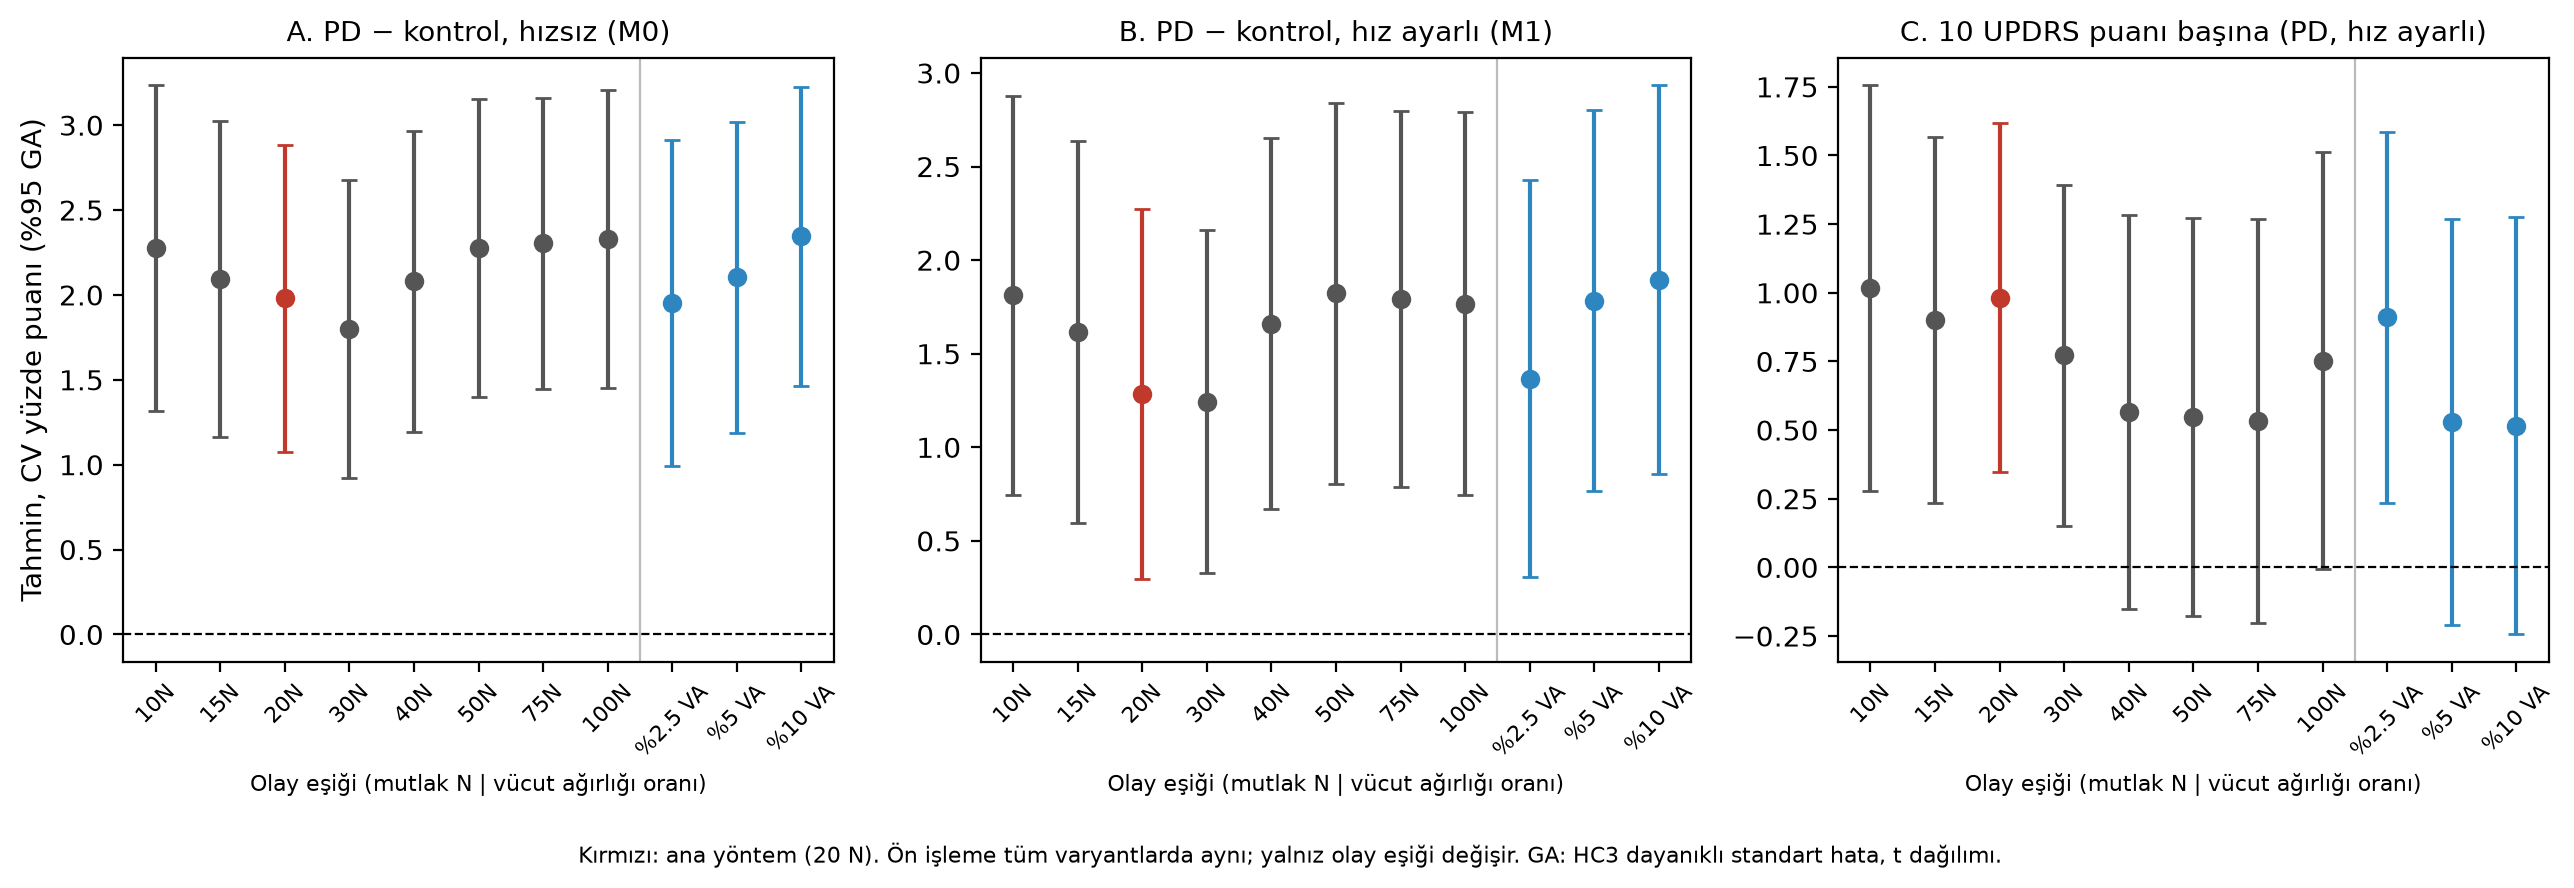

In [13]:
"""E11 — Olay tespiti eşiğine duyarlılık (plan: E11_ESIK_DUYARLILIGI_PLANI.md).

Ön işleme ana yöntemle aynı (ortak.py); yalnız olay eşiği değişir.
1. aşama: her kişi ve her eşik için sol tek destek CV'si → e11_kisi_cv_esik.csv
2. aşama: her eşikte grup ortalamaları, eşleştirmeli Welch farkı, M0/M1 PD katsayısı, şiddet katsayısı
          → tablo_e11_esik_duyarliligi.csv, sekil8_esik_duyarliligi.png
Çalıştırma: python e11_esik_duyarliligi.py   (1. aşama dosyası varsa veri yeniden okunmaz)
"""
import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ortak import ATLA, kayit_oku, on_isleme, temas, tek_destek_araliklari, cv

MUTLAK = [10, 15, 20, 30, 40, 50, 75, 100]      # N
GORELI = [0.025, 0.05, 0.10]                     # vücut ağırlığı oranı
KISI_DOSYA = "e11_kisi_cv_esik.csv"

tablo = pd.read_csv("kisi_cv_tum.csv")           # Hücre 3 örneklemi (164 kişi) ve demografi

# ---------- 1. aşama: kişi bazlı CV ----------
if not os.path.exists(KISI_DOSYA):
    satirlar = []
    for i, s in tablo.iterrows():
        d = kayit_oku(s.ID)
        zaman = d[:, 0]
        bas = zaman >= ATLA
        z, sag_f = zaman[bas], on_isleme(d[:, 18])[bas]
        esikler = [(f"{e}N", e) for e in MUTLAK]
        if pd.notna(s.Weight):
            esikler += [(f"%{100 * o:g}VA", s.Weight * 9.81 * o) for o in GORELI]
        for ad, e in esikler:
            _, basis, kalkis = temas(sag_f, esik=e)
            sure = tek_destek_araliklari(z, basis, kalkis)[:, 1]
            satirlar.append({"ID": s.ID, "esik": ad, "esik_N": e, "n_aralik": len(sure),
                             "ort_s": sure.mean() if len(sure) else np.nan, "CV": cv(sure)})
        if i % 20 == 0:
            print(f"{i + 1}/{len(tablo)} kişi okundu", flush=True)
    pd.DataFrame(satirlar).to_csv(KISI_DOSYA, index=False)

kisi = pd.read_csv(KISI_DOSYA)

# ---------- 2. aşama: modeller ----------
tablo["PD"] = (tablo.Grup == "PD").astype(int)
tablo["UPDRS10"] = tablo.UPDRS / 10

def katsayi(veri, formul, terim):
    m = smf.ols(formul, data=veri).fit(cov_type="HC3", use_t=True)
    alt, ust = m.conf_int().loc[terim]
    return m.params[terim], alt, ust, m.pvalues[terim]

sira = [f"{e}N" for e in MUTLAK] + [f"%{100 * o:g}VA" for o in GORELI]
sonuc = []
for ad in sira:
    v = tablo.drop(columns=["n_aralik", "ort_s"]).merge(kisi[kisi.esik == ad][["ID", "esik_N", "n_aralik", "ort_s", "CV"]], on="ID").dropna(subset=["CV"])
    es = v[v.Patoz_araliginda]
    pd_e, ko_e = es[es.PD == 1].CV, es[es.PD == 0].CV
    w = stats.ttest_ind(pd_e, ko_e, equal_var=False)
    wf = pd_e.mean() - ko_e.mean()
    wa, wu = w.confidence_interval()
    m0 = katsayi(v, "CV ~ PD + C(Study)", "PD")
    m1 = katsayi(v, "CV ~ PD + Speed_01 + C(Study)", "PD")
    pdg = v[(v.PD == 1) & v.UPDRS.notna()]
    sd = katsayi(pdg, "CV ~ UPDRS10 + Speed_01 + C(Study)", "UPDRS10")
    sonuc.append({
        "Eşik": ad, "Eşik N (medyan)": round(v.esik_N.median(), 1), "n": len(v), "n PD": int(v.PD.sum()),
        "Medyan aralık sayısı": int(v.n_aralik.median()), "Ort. tek destek (s)": round(v.ort_s.mean(), 3),
        "CV PD": round(v[v.PD == 1].CV.mean(), 2), "CV kontrol": round(v[v.PD == 0].CV.mean(), 2),
        "Eşleştirmeli fark": wf, "E alt": wa, "E üst": wu, "E p": w.pvalue,
        "M0": m0[0], "M0 alt": m0[1], "M0 üst": m0[2], "M0 p": m0[3],
        "M1": m1[0], "M1 alt": m1[1], "M1 üst": m1[2], "M1 p": m1[3],
        "Şiddet": sd[0], "Ş alt": sd[1], "Ş üst": sd[2], "Ş p": sd[3], "n şiddet": len(pdg),
    })
s = pd.DataFrame(sonuc)
s.round(4).to_csv("tablo_e11_esik_duyarliligi.csv", index=False)

pd.set_option("display.width", 250)
print("\nEşik başına özet (fark ve katsayılar CV yüzde puanı; [HC3 veya Welch %95 GA])")
for _, r in s.iterrows():
    print(f"{r['Eşik']:>7} (~{r['Eşik N (medyan)']:>5} N) n={r.n:3d} aralık={r['Medyan aralık sayısı']:3d} "
          f"ort={r['Ort. tek destek (s)']:.3f}s | CV PD {r['CV PD']:5.2f} K {r['CV kontrol']:5.2f} | "
          f"Eşl {r['Eşleştirmeli fark']:5.2f} [{r['E alt']:5.2f};{r['E üst']:5.2f}] p={r['E p']:.2g} | "
          f"M0 {r.M0:5.2f} [{r['M0 alt']:5.2f};{r['M0 üst']:5.2f}] p={r['M0 p']:.2g} | "
          f"M1 {r.M1:5.2f} [{r['M1 alt']:5.2f};{r['M1 üst']:5.2f}] p={r['M1 p']:.2g} | "
          f"Şiddet {r['Şiddet']:5.2f} [{r['Ş alt']:5.2f};{r['Ş üst']:5.2f}] p={r['Ş p']:.2g}")

# ---------- Doğrulama (planda önceden belirlenen) ----------
print("\nDoğrulama:")
ana = s.set_index("Eşik")
for ad, beklenen in [("20N", (1.98, 1.28, 0.98)), ("50N", (2.28, 1.82, 0.55))]:
    bulunan = tuple(round(ana.loc[ad, k], 2) for k in ["M0", "M1", "Şiddet"])
    print(f"  {ad}: beklenen M0/M1/şiddet {beklenen}, bulunan {bulunan} → {'TAMAM' if bulunan == beklenen else 'FARKLI'}")
eski = pd.read_csv("kisi_cv_tum.csv").set_index("ID")
k20 = kisi[kisi.esik == "20N"].set_index("ID").CV
k50 = kisi[kisi.esik == "50N"].set_index("ID").CV
print(f"  Kişi bazlı en büyük fark: 20N vs CV_ana {np.nanmax(np.abs(k20 - eski.CV_ana.reindex(k20.index))):.2e}, "
      f"50N vs CV_50N {np.nanmax(np.abs(k50 - eski.CV_50N.reindex(k50.index))):.2e}")
m = s.iloc[:len(MUTLAK)]["Ort. tek destek (s)"].values
print("  Mutlak eşik yükseldikçe ortalama tek destek süresi artıyor mu:", bool(np.all(np.diff(m) > 0)), m.round(3).tolist())
print("  PD–kontrol farkının yönü (M0, M1, eşleştirmeli) tüm eşiklerde pozitif mi:",
      bool((s[["M0", "M1", "Eşleştirmeli fark"]] > 0).all().all()))
print("  M1 GA'sı 0'ı dışarıda bırakan eşik sayısı:", int((s["M1 alt"] > 0).sum()), "/", len(s))
print("  Şiddet GA'sı 0'ı dışarıda bırakan eşik sayısı:", int((s["Ş alt"] > 0).sum()), "/", len(s))

# ---------- Şekil 8 ----------
fig, eksen = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True)
x = np.arange(len(s))
paneller = [("M0", "M0 alt", "M0 üst", "A. PD − kontrol, hızsız (M0)"),
            ("M1", "M1 alt", "M1 üst", "B. PD − kontrol, hız ayarlı (M1)"),
            ("Şiddet", "Ş alt", "Ş üst", "C. 10 UPDRS puanı başına (PD, hız ayarlı)")]
for ax, (k, a, u, baslik) in zip(eksen, paneller):
    renk = ["#C0392B" if e == "20N" else ("#555555" if e.endswith("N") else "#2E86C1") for e in s["Eşik"]]
    for xi, (_, r), c in zip(x, s.iterrows(), renk):
        ax.errorbar(xi, r[k], yerr=[[r[k] - r[a]], [r[u] - r[k]]], fmt="o", color=c, capsize=3)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.axvline(len(MUTLAK) - 0.5, color="#BBBBBB", lw=0.8)
    ax.set_title(baslik, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels([e.replace("VA", " VA") for e in s["Eşik"]], rotation=45, fontsize=8)
    ax.set_xlabel("Olay eşiği (mutlak N | vücut ağırlığı oranı)", fontsize=8)
eksen[0].set_ylabel("Tahmin, CV yüzde puanı (%95 GA)")
fig.text(0.5, -0.04, "Kırmızı: ana yöntem (20 N). Ön işleme tüm varyantlarda aynı; yalnız olay eşiği değişir. "
         "GA: HC3 dayanıklı standart hata, t dağılımı.", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig("sekil8_esik_duyarliligi.png", dpi=200, bbox_inches="tight")
print("\nKaydedildi: tablo_e11_esik_duyarliligi.csv, sekil8_esik_duyarliligi.png")

from IPython.display import Image, display
display(Image('sekil8_esik_duyarliligi.png'))

## Hücre 7 — Şekiller ve özet tablo

                   Ölçü Eşleştirilmiş fark (Welch)             Tüm örneklem M0 Tüm örneklem M1 (hız ayarlı) Şiddet: 10 UPDRS başına (hız ayarlı, PD)
             Ana yöntem  1.23 [0.08; 2.39] p=0.037 1.98 [1.08; 2.89] p=2.7e-05    1.28 [0.29; 2.27] p=0.011               0.98 [0.35; 1.62] p=0.0028
       Dönüş ayıklamalı   0.68 [0.11; 1.25] p=0.02 1.55 [0.87; 2.23] p=1.3e-05    0.39 [-0.17; 0.95] p=0.17               0.38 [-0.06; 0.82] p=0.087
      Kalite kuralı yok 2.70 [-0.32; 5.72] p=0.079  2.76 [0.69; 4.84] p=0.0093    2.60 [0.19; 5.01] p=0.034                 1.83 [0.09; 3.57] p=0.04
              50 N eşik  1.49 [0.23; 2.75] p=0.021 2.28 [1.40; 3.15] p=8.4e-07  1.82 [0.80; 2.84] p=0.00054                0.55 [-0.18; 1.27] p=0.14
         Sağ tek destek  0.72 [-0.47; 1.92] p=0.23  1.46 [0.48; 2.44] p=0.0037    0.88 [-0.21; 1.98] p=0.11                0.87 [0.03; 1.72] p=0.044
Eski yöntem (filtresiz)  3.64 [-2.08; 9.37] p=0.21   4.20 [0.37; 8.03] p=0.032   3.93 [-0.50; 8.36] p=0.08


Kısmi regresyon eğimi (Frisch–Waugh kontrolü): 0.982 | tam model: 0.982
Kaydedildi: sekil4_eslestirme_vs_hiz_ayari.png, sekil5_secim_yanliligi.png, sekil6_cv_updrs.png, tablo_duyarlilik_ozeti.csv


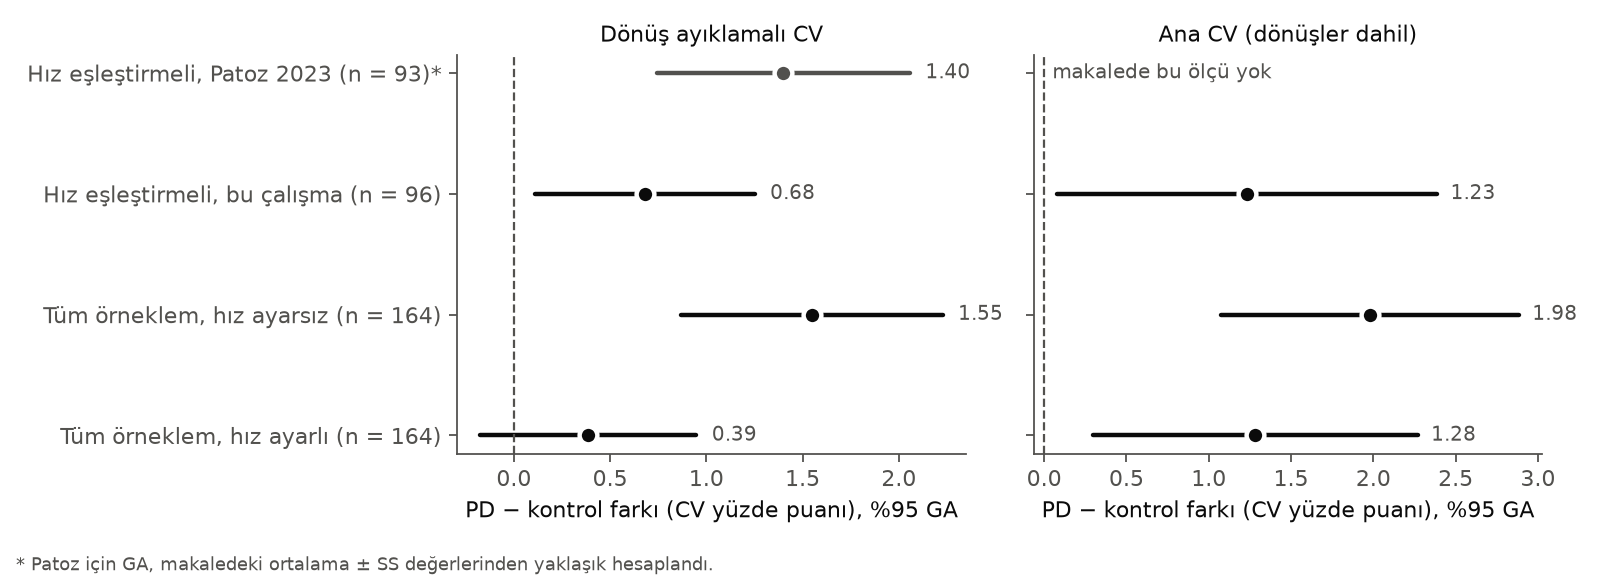

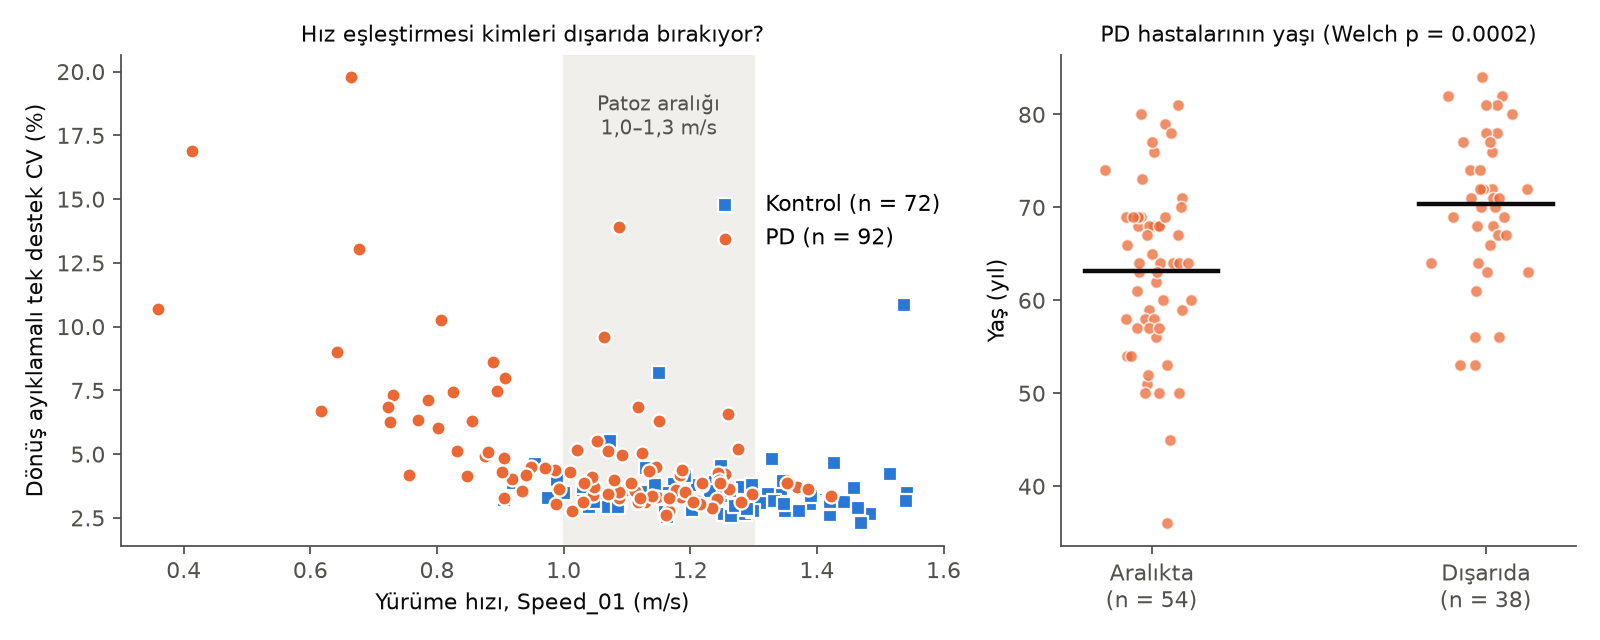

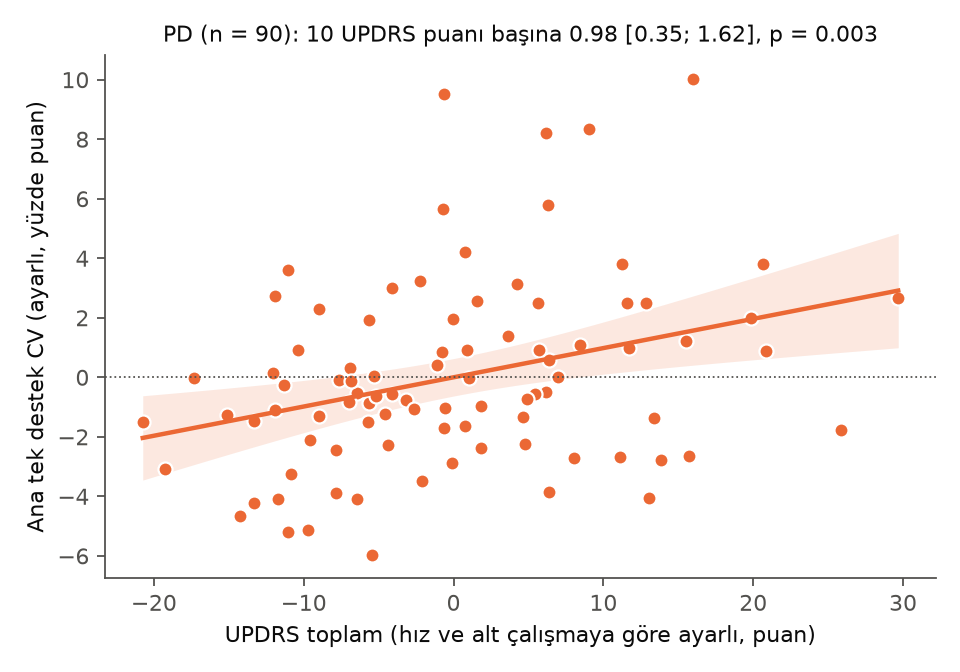

In [14]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats

# Renkler: başvuru paletinin doğrulanmış ilk iki kategorik rengi; grup kimliği ayrıca işaret şekliyle de verilir
RENK = {"PD": "#eb6834", "Kontrol": "#2a78d6"}
ISARET = {"PD": "o", "Kontrol": "s"}
GRI, MUREKKEP = "#52514e", "#0b0b0b"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRI, "axes.labelcolor": MUREKKEP,
                     "xtick.color": GRI, "ytick.color": GRI, "axes.spines.top": False, "axes.spines.right": False})

tablo = pd.read_csv("kisi_cv_tum.csv")
tablo["PD"] = (tablo.Grup == "PD").astype(int)
pdg = tablo[tablo.PD == 1].copy()
pdg["UPDRS10"] = pdg.UPDRS / 10
es = tablo[tablo.Patoz_araliginda]

def welch_fark(veri, y):
    a, b = veri.loc[veri.PD == 1, y], veri.loc[veri.PD == 0, y]
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    df = se ** 4 / ((a.var(ddof=1) / len(a)) ** 2 / (len(a) - 1) + (b.var(ddof=1) / len(b)) ** 2 / (len(b) - 1))
    fark = a.mean() - b.mean()
    return fark, fark - stats.t.ppf(0.975, df) * se, fark + stats.t.ppf(0.975, df) * se, stats.ttest_ind(a, b, equal_var=False).pvalue

def katsayi(veri, formul, terim):
    m = smf.ols(formul, data=veri).fit(cov_type="HC3", use_t=True)
    alt, ust = m.conf_int().loc[terim]
    return m.params[terim], alt, ust, m.pvalues[terim]

# ---------- Duyarlılık özet tablosu ----------
OLCULER = [("CV_ana", "Ana yöntem"), ("CV_donus_ayikli", "Dönüş ayıklamalı"), ("CV_kuralsiz", "Kalite kuralı yok"),
           ("CV_50N", "50 N eşik"), ("CV_sag_tek_destek", "Sağ tek destek"), ("CV_eski", "Eski yöntem (filtresiz)")]
fmt = lambda s: f"{s[0]:.2f} [{s[1]:.2f}; {s[2]:.2f}] p={s[3]:.2g}"
satirlar = []
for y, ad in OLCULER:
    satirlar.append({
        "Ölçü": ad,
        "Eşleştirilmiş fark (Welch)": fmt(welch_fark(es, y)),
        "Tüm örneklem M0": fmt(katsayi(tablo, f"{y} ~ PD + C(Study)", "PD")),
        "Tüm örneklem M1 (hız ayarlı)": fmt(katsayi(tablo, f"{y} ~ PD + Speed_01 + C(Study)", "PD")),
        "Şiddet: 10 UPDRS başına (hız ayarlı, PD)": fmt(katsayi(pdg.dropna(subset=["UPDRS"]), f"{y} ~ UPDRS10 + Speed_01 + C(Study)", "UPDRS10")),
    })
duyarlilik = pd.DataFrame(satirlar)
duyarlilik.to_csv("tablo_duyarlilik_ozeti.csv", index=False)
with pd.option_context("display.width", 250, "display.max_colwidth", 60):
    print(duyarlilik.to_string(index=False))

# ---------- Şekil 4: eşleştirme ve hız ayarı karşılaştırması ----------
p_pd, p_ko = (5.0, 2.1, 54), (3.6, 1.1, 39)
se_p = np.sqrt(p_pd[1] ** 2 / p_pd[2] + p_ko[1] ** 2 / p_ko[2])
patoz = (p_pd[0] - p_ko[0], p_pd[0] - p_ko[0] - 1.96 * se_p, p_pd[0] - p_ko[0] + 1.96 * se_p)
fig, eks = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (y, ad) in zip(eks, [("CV_donus_ayikli", "Dönüş ayıklamalı CV"), ("CV_ana", "Ana CV (dönüşler dahil)")]):
    satir = [("Tüm örneklem, hız ayarlı (n = 164)", katsayi(tablo, f"{y} ~ PD + Speed_01 + C(Study)", "PD")),
             ("Tüm örneklem, hız ayarsız (n = 164)", katsayi(tablo, f"{y} ~ PD + C(Study)", "PD")),
             ("Hız eşleştirmeli, bu çalışma (n = 96)", welch_fark(es, y))]
    satir.append(("Hız eşleştirmeli, Patoz 2023 (n = 93)*", patoz if y == "CV_donus_ayikli" else None))
    for i, (etiket, deger) in enumerate(satir):
        if deger is None:
            ax.text(0.05, i, "makalede bu ölçü yok", va="center", color=GRI, fontsize=9)
            continue
        b, a, u = deger[:3]
        renk = GRI if "Patoz" in etiket else MUREKKEP
        ax.plot([a, u], [i, i], color=renk, lw=2, solid_capstyle="round")
        ax.plot(b, i, "o", color=renk, ms=8, mec="white", mew=2)
        ax.text(u + 0.08, i, f"{b:.2f}", va="center", color=GRI, fontsize=9)
    ax.axvline(0, color=GRI, lw=1, ls="--")
    ax.set_yticks(range(len(satir)), [s[0] for s in satir])
    ax.set_title(ad, color=MUREKKEP, fontsize=10)
    ax.set_xlabel("PD − kontrol farkı (CV yüzde puanı), %95 GA")
fig.text(0.01, 0.01, "* Patoz için GA, makaledeki ortalama ± SS değerlerinden yaklaşık hesaplandı.", fontsize=8, color=GRI)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig("sekil4_eslestirme_vs_hiz_ayari.png", dpi=160)
plt.close()

# ---------- Şekil 5: hız eşleştirmesinin dışarıda bıraktıkları ----------
fig, eks = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = eks[0]
ax.axvspan(1.0, 1.3, color="#f0efec", zorder=0)
ax.text(1.15, tablo.CV_donus_ayikli.max() * 0.97, "Patoz aralığı\n1,0–1,3 m/s", ha="center", va="top", color=GRI, fontsize=9)
for g in ["Kontrol", "PD"]:
    v = tablo[tablo.Grup == g]
    ax.scatter(v.Speed_01, v.CV_donus_ayikli, s=40, marker=ISARET[g], color=RENK[g], edgecolor="white", linewidth=1, label=f"{g} (n = {len(v)})", zorder=2)
ax.set_xlabel("Yürüme hızı, Speed_01 (m/s)")
ax.set_ylabel("Dönüş ayıklamalı tek destek CV (%)")
ax.legend(frameon=False, loc="center right", bbox_to_anchor=(1.02, 0.66))
ax.set_title("Hız eşleştirmesi kimleri dışarıda bırakıyor?", color=MUREKKEP, fontsize=10)
ax = eks[1]
gruplar = [("aralıkta", pdg[pdg.Patoz_araliginda]), ("dışarıda", pdg[~pdg.Patoz_araliginda])]
for i, (ad, v) in enumerate(gruplar):
    x = np.random.default_rng(i).normal(i, 0.06, len(v))
    ax.scatter(x, v.Age, s=30, marker="o", color=RENK["PD"], alpha=0.75, edgecolor="white", linewidth=0.8)
    ax.plot([i - 0.2, i + 0.2], [v.Age.mean()] * 2, color=MUREKKEP, lw=2)
ax.set_xticks([0, 1], [f"Aralıkta\n(n = {len(gruplar[0][1])})", f"Dışarıda\n(n = {len(gruplar[1][1])})"])
ax.set_ylabel("Yaş (yıl)")
ax.set_title(f"PD hastalarının yaşı (Welch p = {stats.ttest_ind(gruplar[1][1].Age, gruplar[0][1].Age, equal_var=False).pvalue:.4f})", color=MUREKKEP, fontsize=10)
plt.tight_layout()
plt.savefig("sekil5_secim_yanliligi.png", dpi=160)
plt.close()

# ---------- Şekil 6: CV ile UPDRS (hız ve alt çalışma ayarlı kısmi ilişki) ----------
v = pdg.dropna(subset=["UPDRS"]).copy()
v["CV_art"] = smf.ols("CV_ana ~ Speed_01 + C(Study)", data=v).fit().resid
v["UPDRS_art"] = smf.ols("UPDRS10 ~ Speed_01 + C(Study)", data=v).fit().resid
m = smf.ols("CV_art ~ UPDRS_art", data=v).fit()
xs = np.linspace(v.UPDRS_art.min(), v.UPDRS_art.max(), 100)
tah = m.get_prediction(pd.DataFrame({"UPDRS_art": xs})).summary_frame()
b, a, u, p = katsayi(v, "CV_ana ~ UPDRS10 + Speed_01 + C(Study)", "UPDRS10")
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill_between(xs * 10, tah.mean_ci_lower, tah.mean_ci_upper, color=RENK["PD"], alpha=0.15, lw=0)
ax.plot(xs * 10, tah["mean"], color=RENK["PD"], lw=2)
ax.scatter(v.UPDRS_art * 10, v.CV_art, s=40, color=RENK["PD"], edgecolor="white", linewidth=1)
ax.axhline(0, color=GRI, lw=0.8, ls=":")
ax.set_xlabel("UPDRS toplam (hız ve alt çalışmaya göre ayarlı, puan)")
ax.set_ylabel("Ana tek destek CV (ayarlı, yüzde puan)")
ax.set_title(f"PD (n = {len(v)}): 10 UPDRS puanı başına {b:.2f} [{a:.2f}; {u:.2f}], p = {p:.3f}", color=MUREKKEP, fontsize=10)
plt.tight_layout()
plt.savefig("sekil6_cv_updrs.png", dpi=160)
plt.close()
print("\nKısmi regresyon eğimi (Frisch–Waugh kontrolü):", round(m.params.UPDRS_art, 3), "| tam model:", round(b, 3))
print("Kaydedildi: sekil4_eslestirme_vs_hiz_ayari.png, sekil5_secim_yanliligi.png, sekil6_cv_updrs.png, tablo_duyarlilik_ozeti.csv")

from IPython.display import Image, display
for f in ['sekil4_eslestirme_vs_hiz_ayari.png', 'sekil5_secim_yanliligi.png', 'sekil6_cv_updrs.png']:
    display(Image(f))

## E10 — Katılımcı akışı ve dönüş tespiti şekilleri

Sayılar: ['GaitPDB v1.0.0 demografi | 166 kişi (93 PD, 73 kontrol)', 'Olağan yürüyüş hızı (Speed_01) dolu | 165 kişi', 'Analiz örneklemi | 164 kişi (92 PD, 72 kontrol) | Ga 46 · Ju 54 · Si 64', 'Hız eşleştirmesi (1,0–1,3 m/s) | 54 PD + 42 kontrol', 'Şiddet analizi (yalnız PD, UPDRS dolu) | 90 PD', 'Çıkarıldı: hız eksik | 1 PD (GaPt03)', 'Çıkarıldı: kayıt dosyası yok | 1 kontrol (Juc010)']


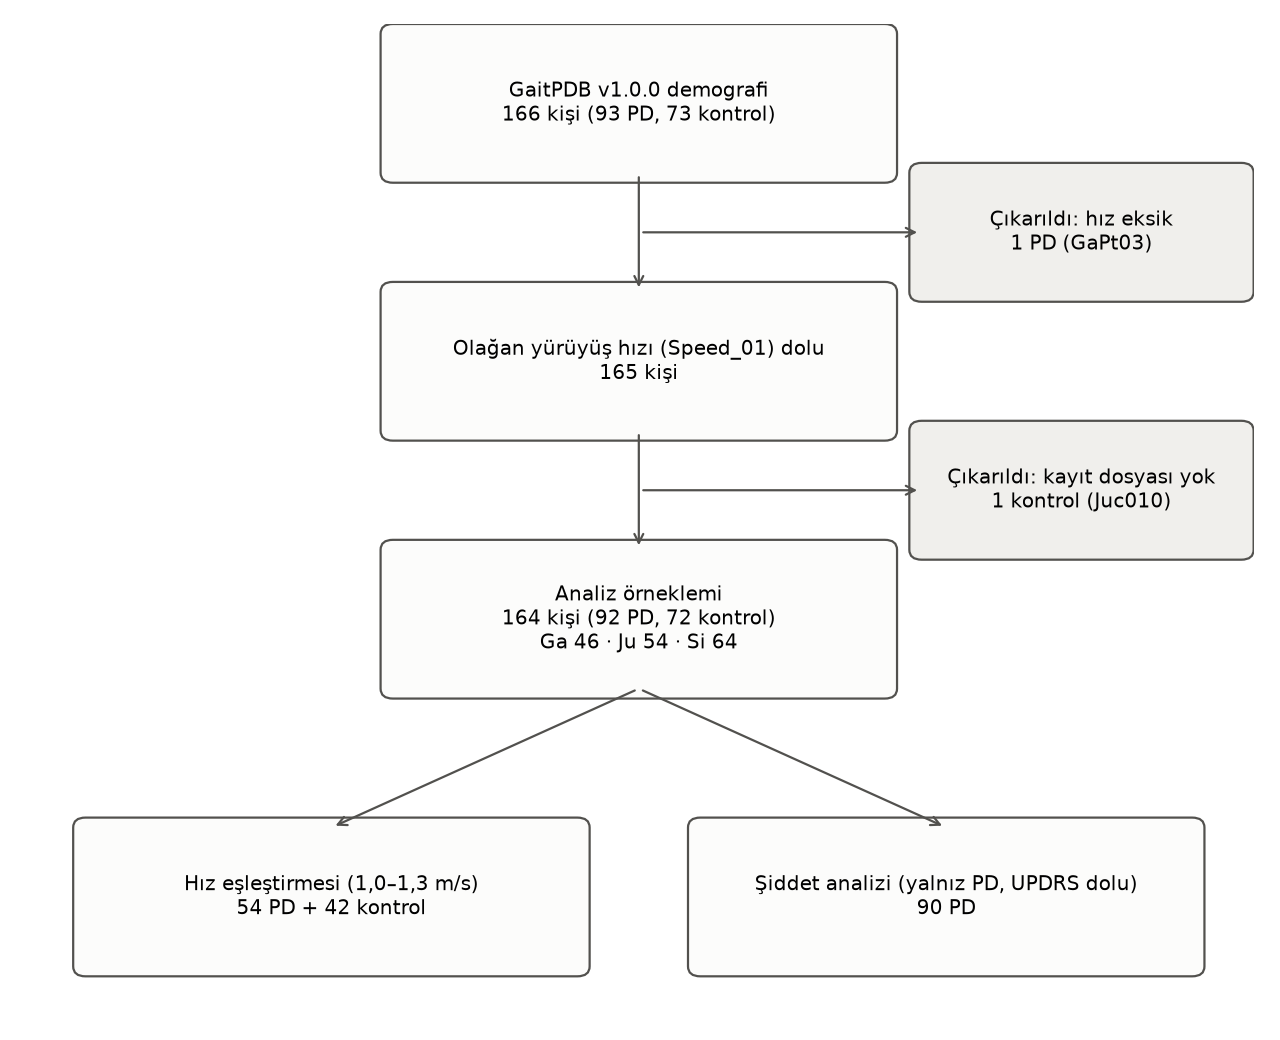

In [15]:
"""Şekil 1 — Katılımcı akış şeması (STROBE 13a). Sayılar demografi ve kisi_cv_tum_e2.csv'den hesaplanır."""
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

URL = "https://physionet-open.s3.amazonaws.com/gaitpdb/1.0.0/"
dem = pd.read_csv(URL + "demographics.txt", sep="\t", usecols=range(20))
dem = dem[dem.ID.notna()]
t = pd.read_csv("kisi_cv_tum_e2.csv")
n = lambda v, g: int((v.Group == g).sum())
hiz_yok = dem[dem.Speed_01.isna()]
kutu = [
    (0.5, 0.92, f"GaitPDB v1.0.0 demografi\n{len(dem)} kişi ({n(dem, 1)} PD, {n(dem, 2)} kontrol)"),
    (0.5, 0.66, f"Olağan yürüyüş hızı (Speed_01) dolu\n{len(dem) - len(hiz_yok)} kişi"),
    (0.5, 0.40, f"Analiz örneklemi\n{len(t)} kişi ({(t.Grup == 'PD').sum()} PD, {(t.Grup == 'Kontrol').sum()} kontrol)\nGa {int((t.Study == 'Ga').sum())} · Ju {int((t.Study == 'Ju').sum())} · Si {int((t.Study == 'Si').sum())}"),
    (0.25, 0.12, f"Hız eşleştirmesi (1,0–1,3 m/s)\n{int((t.Patoz_araliginda & (t.Grup == 'PD')).sum())} PD + {int((t.Patoz_araliginda & (t.Grup == 'Kontrol')).sum())} kontrol"),
    (0.75, 0.12, f"Şiddet analizi (yalnız PD, UPDRS dolu)\n{int(((t.Grup == 'PD') & t.UPDRS.notna()).sum())} PD"),
]
dis = [(0.86, 0.79, f"Çıkarıldı: hız eksik\n{len(hiz_yok)} PD ({', '.join(hiz_yok.ID)})"),
       (0.86, 0.53, "Çıkarıldı: kayıt dosyası yok\n1 kontrol (Juc010)")]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.axis("off")
for x, y, s in kutu + dis:
    ax.add_patch(FancyBboxPatch((x - 0.2, y - 0.07), 0.4 if (x, y, s) in kutu else 0.26, 0.14, boxstyle="round,pad=0.01",
                                fc="#fcfcfb", ec="#52514e", lw=1, transform=ax.transAxes) if (x, y, s) in kutu else
                 FancyBboxPatch((x - 0.13, y - 0.06), 0.26, 0.12, boxstyle="round,pad=0.01", fc="#f0efec", ec="#52514e", lw=1, transform=ax.transAxes))
    ax.text(x, y, s, ha="center", va="center", fontsize=9, transform=ax.transAxes)
for (y0, y1) in [(0.85, 0.73), (0.59, 0.47)]:
    ax.annotate("", xy=(0.5, y1), xytext=(0.5, y0), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", color="#52514e"))
for y in [0.79, 0.53]:
    ax.annotate("", xy=(0.73, y), xytext=(0.5, y), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", color="#52514e"))
for x in [0.25, 0.75]:
    ax.annotate("", xy=(x, 0.19), xytext=(0.5, 0.33), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", color="#52514e"))
plt.tight_layout()
plt.savefig("sekil1_katilimci_akisi.png", dpi=160)
print("Sayılar:", [s.replace("\n", " | ") for _, _, s in kutu + dis])

from IPython.display import Image, display
display(Image('sekil1_katilimci_akisi.png'))

sekil7_donus_tespiti.png kaydedildi


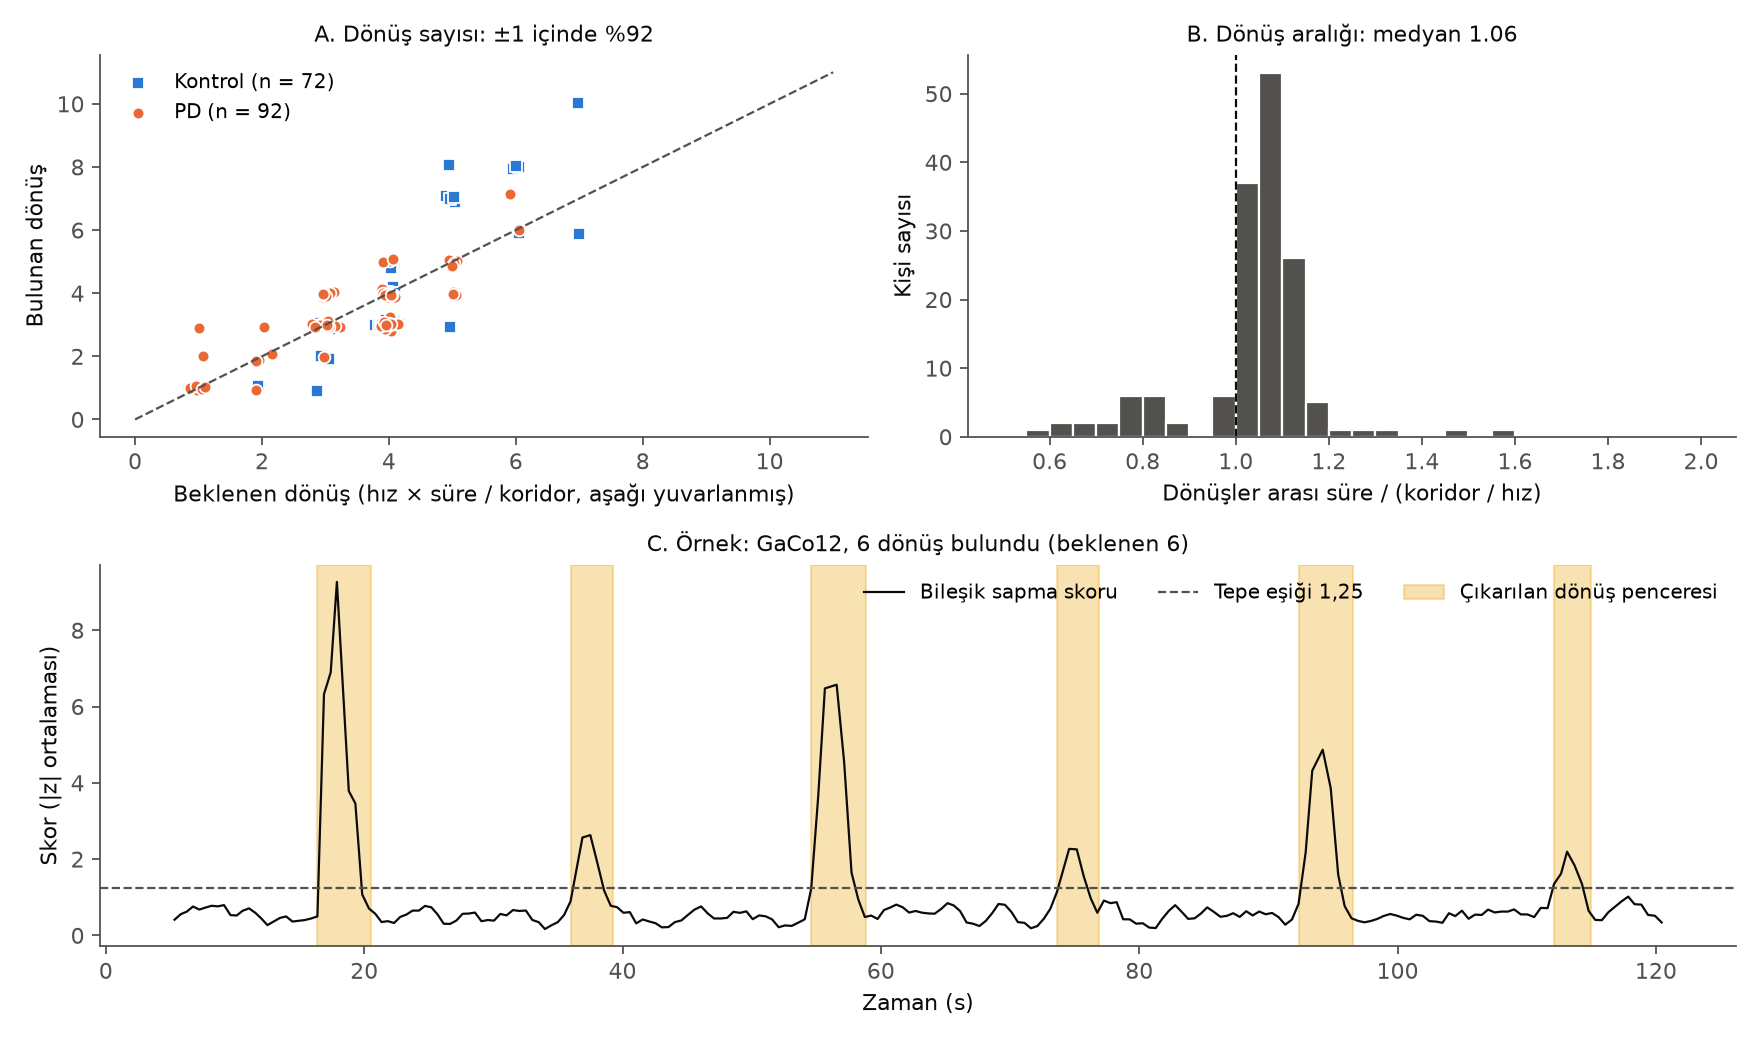

In [16]:
"""Şekil 7 — COP tabanlı dönüş tespitinin doğrulaması."""
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from e2b_donus_tespiti_v2 import skor, KORIDOR

GRI, MUREKKEP = "#52514e", "#0b0b0b"
RENK = {"PD": "#eb6834", "Kontrol": "#2a78d6"}
ISARET = {"PD": "o", "Kontrol": "s"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRI})
with open("e2_donus_v2.pkl", "rb") as f:
    s = pickle.load(f)
with open("adim_olaylari.pkl", "rb") as f:
    ol = pickle.load(f)
s["beklenen_tam"] = np.floor(s.beklenen)
fig = plt.figure(figsize=(11, 6.5))
ax1 = fig.add_subplot(2, 2, 1)
rng = np.random.default_rng(1)
for g in ["Kontrol", "PD"]:
    v = s[s.Grup == g]
    ax1.scatter(v.beklenen_tam + rng.normal(0, 0.08, len(v)), v.n_donus + rng.normal(0, 0.08, len(v)), s=28, marker=ISARET[g],
                color=RENK[g], edgecolor="white", linewidth=0.8, label=f"{g} (n = {len(v)})")
m = int(max(s.beklenen_tam.max(), s.n_donus.max())) + 1
ax1.plot([0, m], [0, m], color=GRI, ls="--", lw=1)
ax1.set_xlabel("Beklenen dönüş (hız × süre / koridor, aşağı yuvarlanmış)")
ax1.set_ylabel("Bulunan dönüş")
ax1.legend(frameon=False, fontsize=9)
ax1.set_title(f"A. Dönüş sayısı: ±1 içinde %{100 * ((s.n_donus - s.beklenen_tam).abs() <= 1).mean():.0f}", fontsize=10, color=MUREKKEP)
ax2 = fig.add_subplot(2, 2, 2)
ax2.hist(s.oran_arasi.dropna(), bins=np.arange(0.5, 2.05, 0.05), color=GRI, edgecolor="white")
ax2.axvline(1, color=MUREKKEP, ls="--", lw=1)
ax2.set_xlabel("Dönüşler arası süre / (koridor / hız)")
ax2.set_ylabel("Kişi sayısı")
ax2.set_title(f"B. Dönüş aralığı: medyan {s.oran_arasi.median():.2f}", fontsize=10, color=MUREKKEP)
ax3 = fig.add_subplot(2, 1, 2)
k = "GaCo12"
d, sk = skor(ol[k]["duruslar"])
r = s.set_index("ID").loc[k]
ax3.plot(d.bas_t, sk, color=MUREKKEP, lw=1, label="Bileşik sapma skoru")
ax3.axhline(1.25, color=GRI, ls="--", lw=1, label="Tepe eşiği 1,25")
for i, (a, b, c) in enumerate(r.pencereler):
    ax3.axvspan(a, b, color="#eda100", alpha=0.3, label="Çıkarılan dönüş penceresi" if i == 0 else None)
ax3.set_xlabel("Zaman (s)")
ax3.set_ylabel("Skor (|z| ortalaması)")
ax3.legend(frameon=False, fontsize=9, loc="upper right", ncol=3)
ax3.set_title(f"C. Örnek: {k}, {r.n_donus} dönüş bulundu (beklenen {int(r.beklenen)})", fontsize=10, color=MUREKKEP)
plt.tight_layout()
plt.savefig("sekil7_donus_tespiti.png", dpi=160)
print("sekil7_donus_tespiti.png kaydedildi")

display(Image('sekil7_donus_tespiti.png'))

## Yeniden üretim kontrolü
Bu defterin baştan ürettiği tablolar, `10_Analiz_Genisletilmis/` klasöründeki önceki tablolarla karşılaştırılır.

In [17]:
import os, numpy as np, pandas as pd
ONCEKI = os.path.join('..', '10_Analiz_Genisletilmis')
for f in ['kisi_cv_tum.csv', 'kisi_cv_tum_e2.csv', 'tablo_patoz_tekrari.csv', 'tablo_tum_orneklem_modeller.csv',
          'tablo_siddet_modelleri.csv', 'tablo_e1_guvenilirlik.csv', 'tablo_e_cekirdek.csv', 'tablo_duyarlilik_ozeti.csv',
          'tablo_e11_esik_duyarliligi.csv']:
    yeni, eski = pd.read_csv(f), pd.read_csv(os.path.join(ONCEKI, f))
    if yeni.shape != eski.shape or list(yeni.columns) != list(eski.columns):
        print(f'{f}: BİÇİM FARKLI', yeni.shape, eski.shape); continue
    sayi = yeni.select_dtypes('number').columns
    fark = np.nanmax(np.abs(yeni[sayi].to_numpy(float) - eski[sayi].to_numpy(float))) if len(sayi) else 0.0
    metin_ayni = yeni.drop(columns=sayi).astype(str).equals(eski.drop(columns=sayi).astype(str))
    print(f'{f}: sayısal en büyük fark {fark:.2e} | metin sütunları aynı: {metin_ayni}')

kisi_cv_tum.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
kisi_cv_tum_e2.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_patoz_tekrari.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_tum_orneklem_modeller.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_siddet_modelleri.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_e1_guvenilirlik.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_e_cekirdek.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_duyarlilik_ozeti.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
tablo_e11_esik_duyarliligi.csv: sayısal en büyük fark 0.00e+00 | metin sütunları aynı: True
